# Title:- Portuguese Bank Marketing Project
## **Project Introduction – Portuguese Bank Marketing Prediction**

My project is **Portuguese Bank Marketing Prediction**, which belongs to the Finance and Banking domain. The main objective of this project is to predict whether a customer will subscribe to a term deposit based on their personal details, financial information, and previous marketing campaign interactions.

The bank conducts marketing campaigns through phone calls, but contacting every customer is time-consuming and expensive. So, we use Machine Learning classification algorithms to identify customers who are more likely to subscribe.

By analyzing customer data, we aim to help the bank improve its marketing strategy, increase subscription rates, and reduce unnecessary marketing costs.

**Technologies used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn and Jupyter Notebook.

## **1. Problem Statement**

The Portuguese bank conducts direct marketing campaigns through phone calls to promote term deposits. However, contacting every customer is time-consuming and expensive. The problem is to develop a Machine Learning model that predicts whether a customer will subscribe to a term deposit or not.

## **2. Business Objective**

The main business objective is to help the bank identify potential customers who are more likely to subscribe to term deposits. This will help the bank improve marketing campaign effectiveness, increase customer subscriptions, reduce unnecessary phone calls, and save marketing costs.

## **Importing Libraries**

In this step, we import the required Python libraries for our project. These libraries help us perform data manipulation, numerical calculations, data visualization, and Machine Learning model development.

We use:

- **Pandas:** To load and manipulate the dataset.
- **NumPy:** To perform numerical operations.
- **Matplotlib:** To create graphs and visualizations.
- **Seaborn:** To create statistical visualizations.
- **Scikit-learn:** To perform data preprocessing, train Machine Learning models, and evaluate model performance.

**Purpose:** Importing these libraries makes our data analysis and model-building process easier and more efficient.

In [63]:
#let's start with importing necessary libraries 
import numpy as np 
import pandas as pd 
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

## Businesscase:- To predict the client of the bank will subscribed a term deposit or not?
 **Binary classification**

 ## **Dataset Loading**

In this step, we load the Portuguese Bank Marketing dataset (`bank-additional-full.csv`) into our Python environment using the Pandas library. The dataset contains customer information, previous marketing campaign details, and the target variable (`y`), which indicates whether a customer subscribed to a term deposit.

**Purpose:** To import the dataset into a DataFrame so that we can perform data analysis, data cleaning, and further Machine Learning operations.

In [64]:
## read the dataset 
data=pd.read_csv(r"D:\bank-additional-full.csv",sep=';',na_values='unknow')
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


## **Data Understanding**

In this step, we examine the dataset to understand its structure, size, columns, and data types. We check the first few records, missing values, duplicate records, statistical summaries, and the distribution of the target variable (`y`).

**Purpose:** To understand the dataset, identify data quality issues, and gain basic insights before performing data cleaning and exploratory data analysis (EDA).

In [65]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [66]:
data.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [67]:
data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [68]:
data.describe(include='O')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


In [69]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

# 1. Basic Understanding of Features – Domain Analysis

## 1.1 Introduction

The dataset contains information about bank clients, their previous marketing campaign interactions, and various social and economic indicators. The main objective of this dataset is to predict whether a client will subscribe to a term deposit based on the available input features.

The dataset consists of **20 independent variables (features)** and **1 dependent variable (target)**.

## 1.2 Input Variables (Independent Features)

The input variables are divided into four major categories based on their characteristics.

### A. Bank Client Data

These features provide personal and financial information about the bank's clients.

1. **Age:** Represents the age of the client. It is a numerical variable.
2. **Job:** Describes the occupation of the client. It is a categorical variable with values such as admin, blue-collar, entrepreneur, management, retired, student, technician, and others.
3. **Marital:** Indicates the marital status of the client. Possible values include divorced, married, single, and unknown. Here, divorced also includes widowed clients.
4. **Education:** Represents the highest educational qualification of the client. Categories include basic.4y, basic.6y, basic.9y, high.school, illiterate, professional.course, university.degree, and unknown.
5. **Default:** Indicates whether the client has credit in default. Possible values are yes, no, and unknown.
6. **Housing:** Indicates whether the client has a housing loan. Possible values are yes, no, and unknown.
7. **Loan:** Indicates whether the client has a personal loan. Possible values are yes, no, and unknown.

### B. Features Related to the Last Contact of the Current Campaign

These features describe the communication details of the bank's most recent contact with the client.

8. **Contact:** Specifies the type of communication used to contact the client. Possible values are cellular and telephone.
9. **Month:** Represents the month in which the client was last contacted. Values range from January to December.
10. **Day_of_week:** Indicates the day of the week on which the client was last contacted. Possible values are Monday, Tuesday, Wednesday, Thursday, and Friday.
11. **Duration:** Represents the duration of the last contact in seconds. This is a numerical variable.

**Important Note:** The duration feature has a significant influence on the target variable. For example, if the duration is 0 seconds, the target variable will be "no". However, this feature is not known before making a call. Therefore, if the objective is to build a realistic predictive model before contacting the client, the duration feature should be excluded to avoid data leakage. It can be retained only for benchmarking purposes.

### C. Other Campaign-Related Attributes

These features provide information about the client's previous interactions with the bank's marketing campaigns.

12. **Campaign:** Represents the number of contacts performed during the current marketing campaign for a particular client, including the last contact. It is a numerical variable.
13. **Pdays:** Indicates the number of days that passed since the client was last contacted during a previous marketing campaign. A value of 999 means that the client was not previously contacted.
14. **Previous:** Represents the number of contacts performed before the current marketing campaign for a particular client.
15. **Poutcome:** Indicates the outcome of the previous marketing campaign. Possible values are failure, nonexistent, and success.

### D. Social and Economic Context Attributes

These features represent the social and economic conditions that may influence a client's decision to subscribe to a term deposit.

16. **Emp.var.rate:** Represents the employment variation rate, which is a quarterly economic indicator.
17. **Cons.price.idx:** Represents the consumer price index, which is a monthly economic indicator.
18. **Cons.conf.idx:** Represents the consumer confidence index, which is a monthly economic indicator.
19. **Euribor3m:** Represents the three-month Euribor interest rate, which is a daily economic indicator.
20. **Nr.employed:** Represents the number of employees, which is a quarterly economic indicator.



## Exploratory Data Analysis:-

**univariate Analysis**

In [70]:
data.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [71]:
## renaming certain columns just to make analysis easy 
data.rename(columns={'emp.var.rate':'emp_var_rate','cons.price.idx':'cons_price_idx',
                     'cons.conf.idx':'cons_conf_idx',
                     'nr.employed':'nr_employed'}
            ,inplace=True)

In [72]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [73]:
%pip install sweetviz

Note: you may need to restart the kernel to use updated packages.


In [74]:
##!pip install sweetviz
import sweetviz as sv
my_report = sv.analyze(data)## pass the original dataframe 
my_report.show_html()#Default argument will generate to "SWEETVIZ_REPORT.html"

                                             |          | [  0%]   00:00 -> (? left)

Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


## Bivariate or Multivariate Analysis

In [75]:
data1=data[['age','duration','campaign','pdays','previous','emp_var_rate',
           'cons_price_idx','cons_conf_idx','euribor3m','nr_employed']]
data1

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0
3,40,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0
4,56,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0
...,...,...,...,...,...,...,...,...,...,...
41183,73,334,1,999,0,-1.1,94.767,-50.8,1.028,4963.6
41184,46,383,1,999,0,-1.1,94.767,-50.8,1.028,4963.6
41185,56,189,2,999,0,-1.1,94.767,-50.8,1.028,4963.6
41186,44,442,1,999,0,-1.1,94.767,-50.8,1.028,4963.6


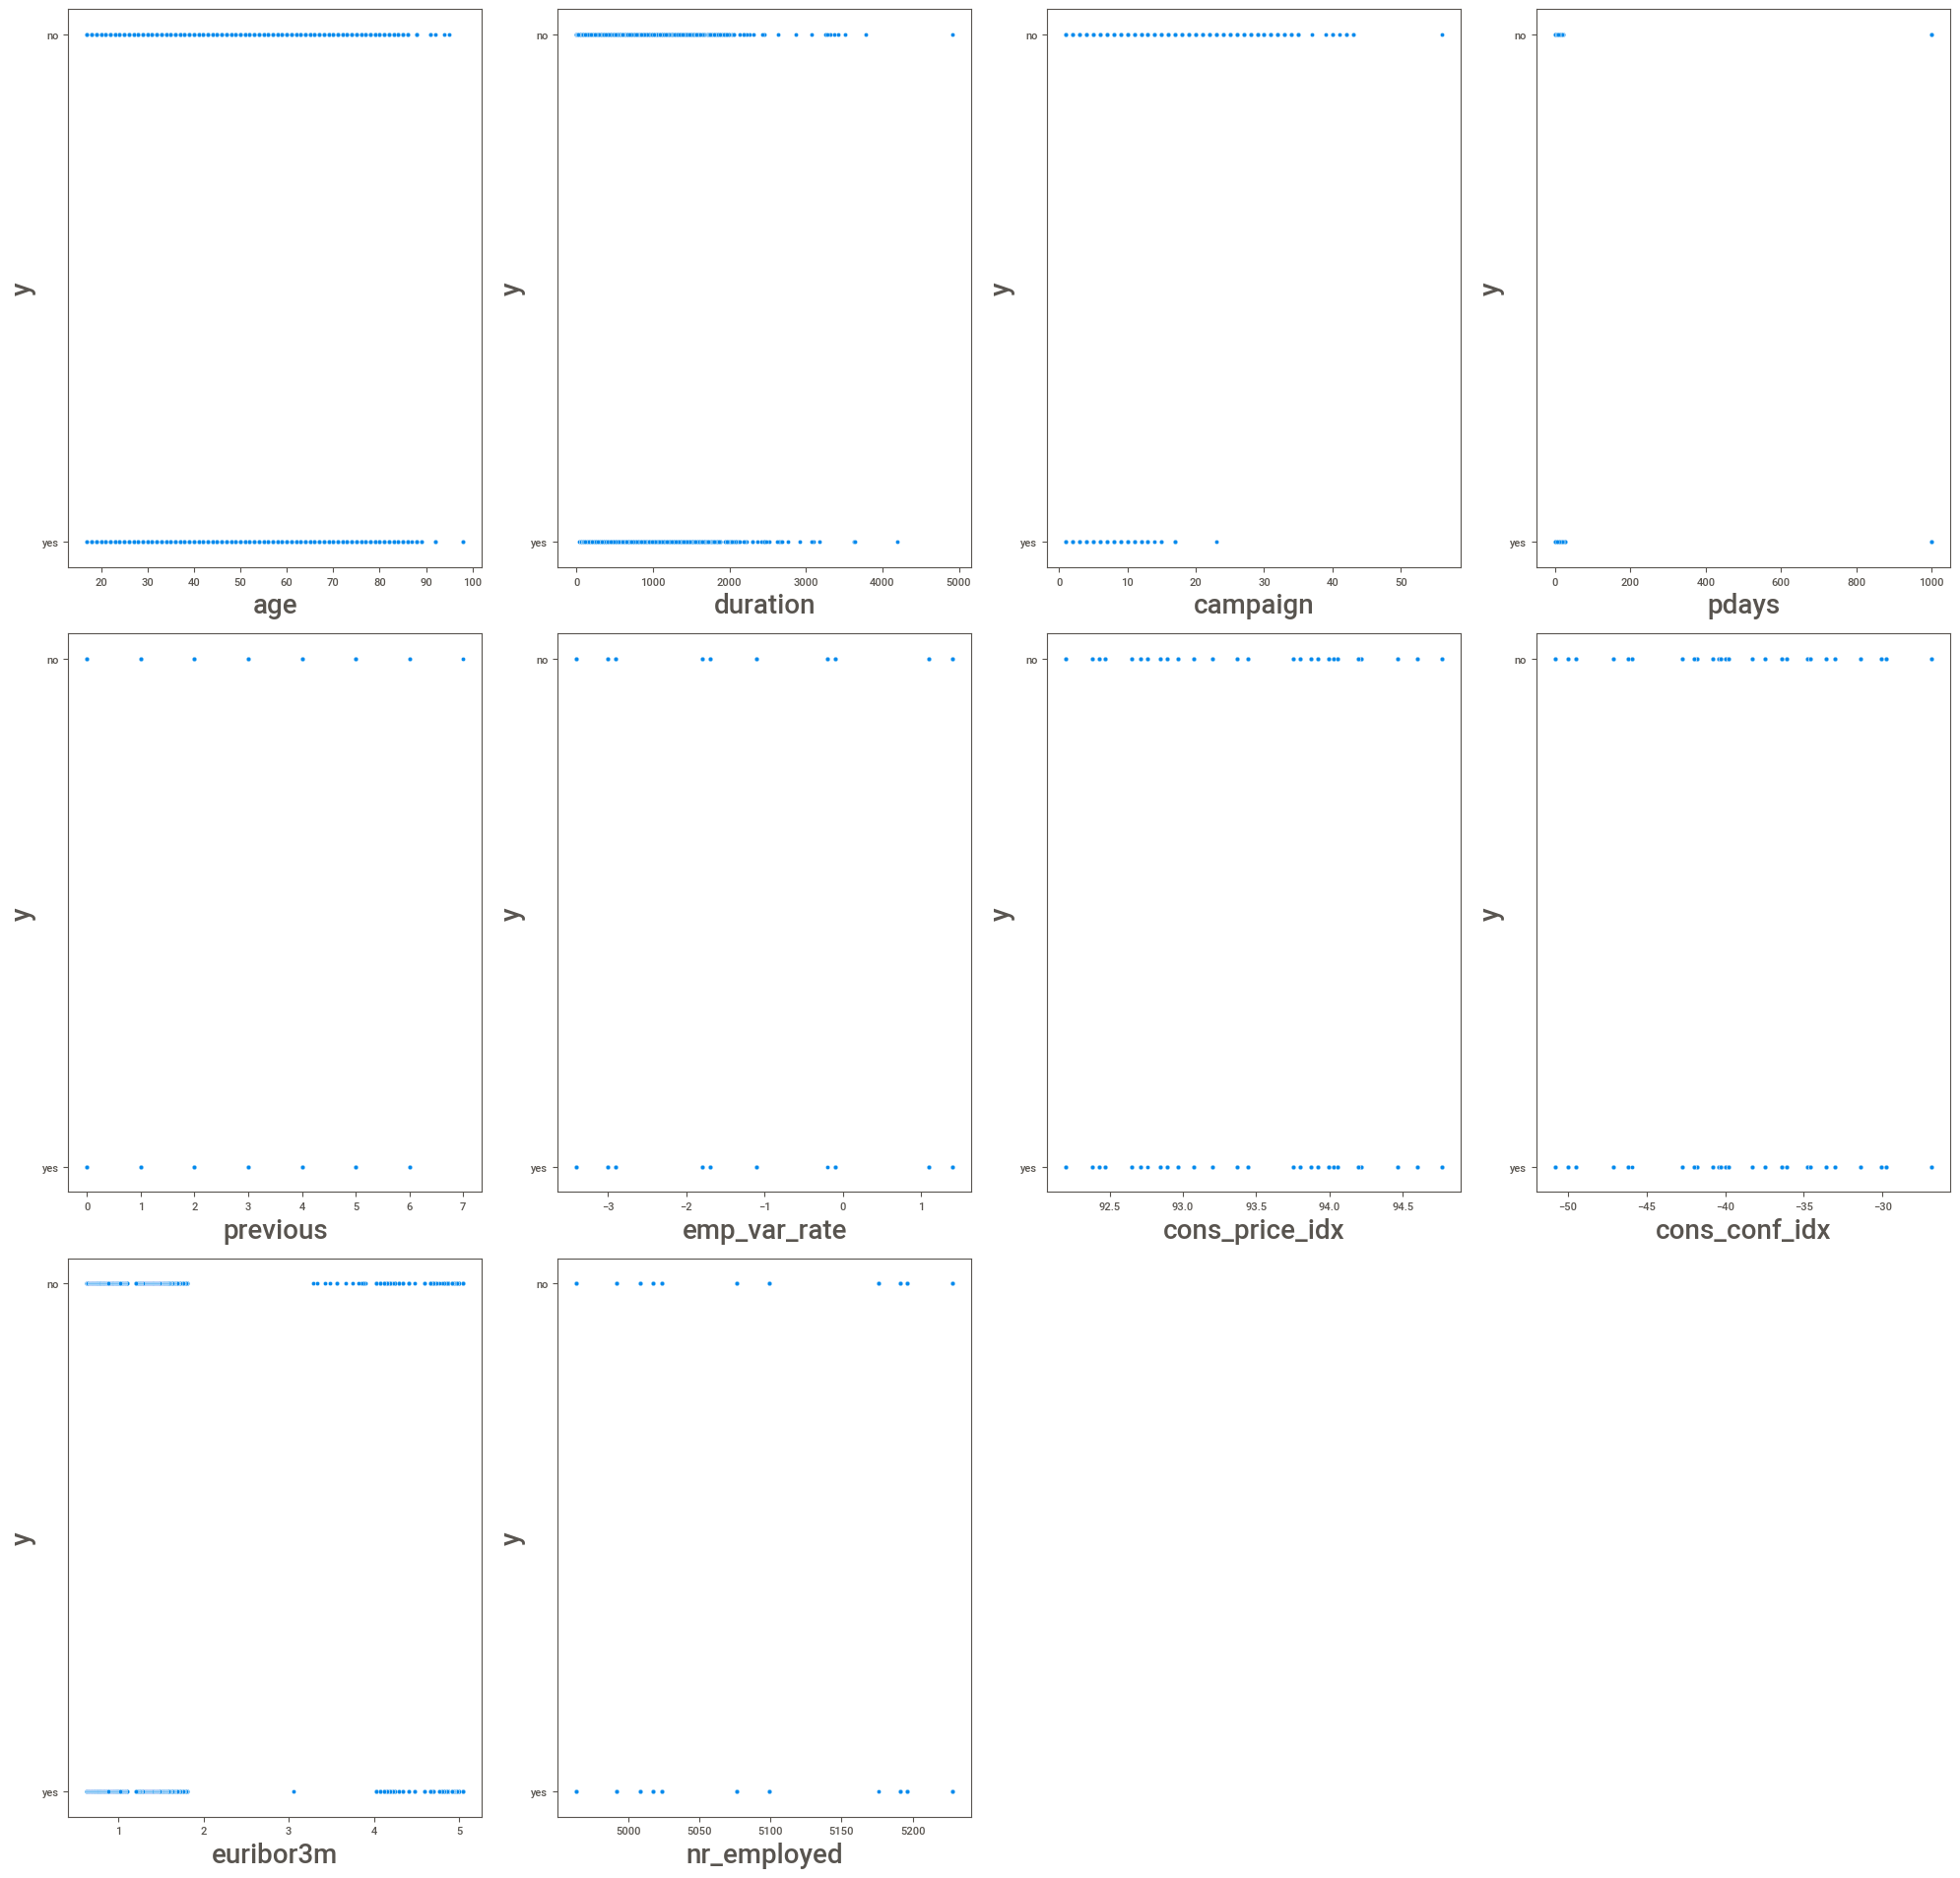

In [76]:
plt.figure(figsize=(20,25),facecolor="white")
plotnumber = 1
for column in data1:
    if plotnumber<=10: ## as there is 10 columns 
        ax = plt.subplot(4,4, plotnumber)
        sns.scatterplot(x=data1[column].dropna(axis=0)
                        ,y=data.y)
        plt.xlabel(column,fontsize=20)
        plt.ylabel('y',fontsize=20)
    plotnumber+=1
plt.tight_layout()    


Great, the relationship between the dependent and independent variables look fairly linear. Thus, our linearity assumption is satisfied

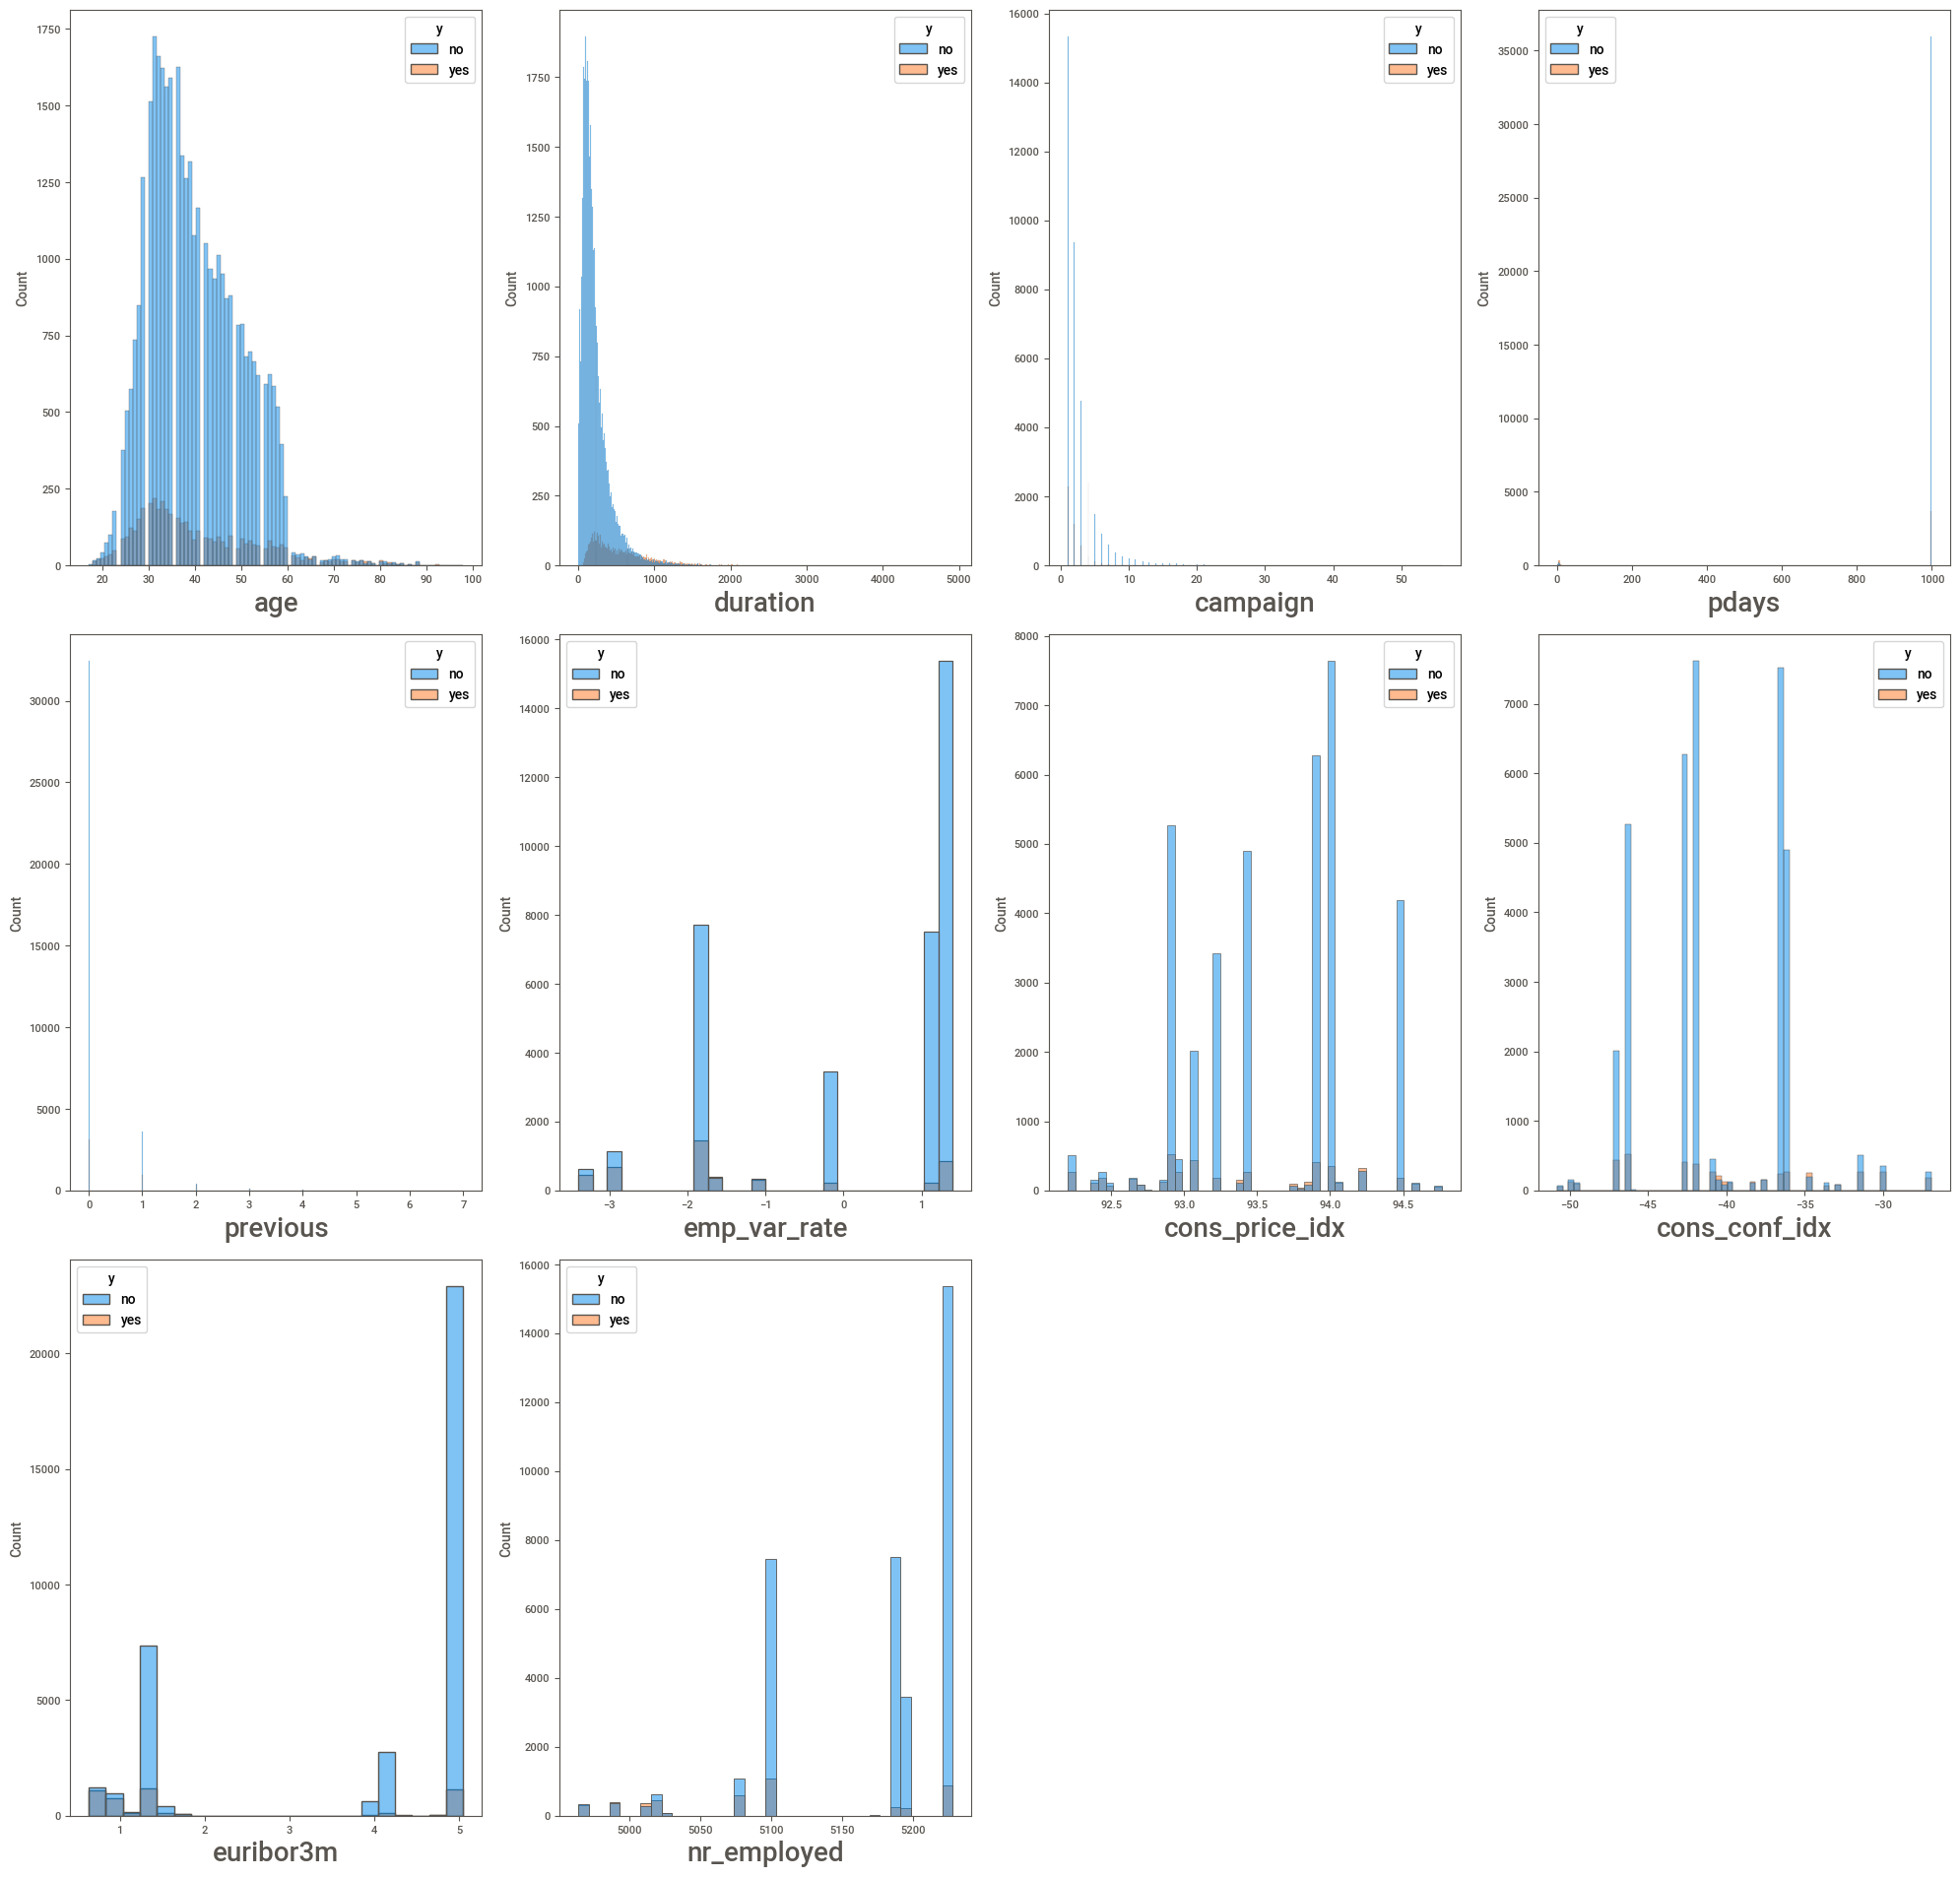

In [77]:
plt.figure(figsize=(20,25),facecolor="white")
plotnumber = 1

for column in data1:
    if plotnumber<=10 :
        ax=plt.subplot(4,4,plotnumber)
        sns.histplot(x=data1[column],hue=data.y)
        plt.xlabel(column,fontsize=20)
    plotnumber+=1
plt.tight_layout()

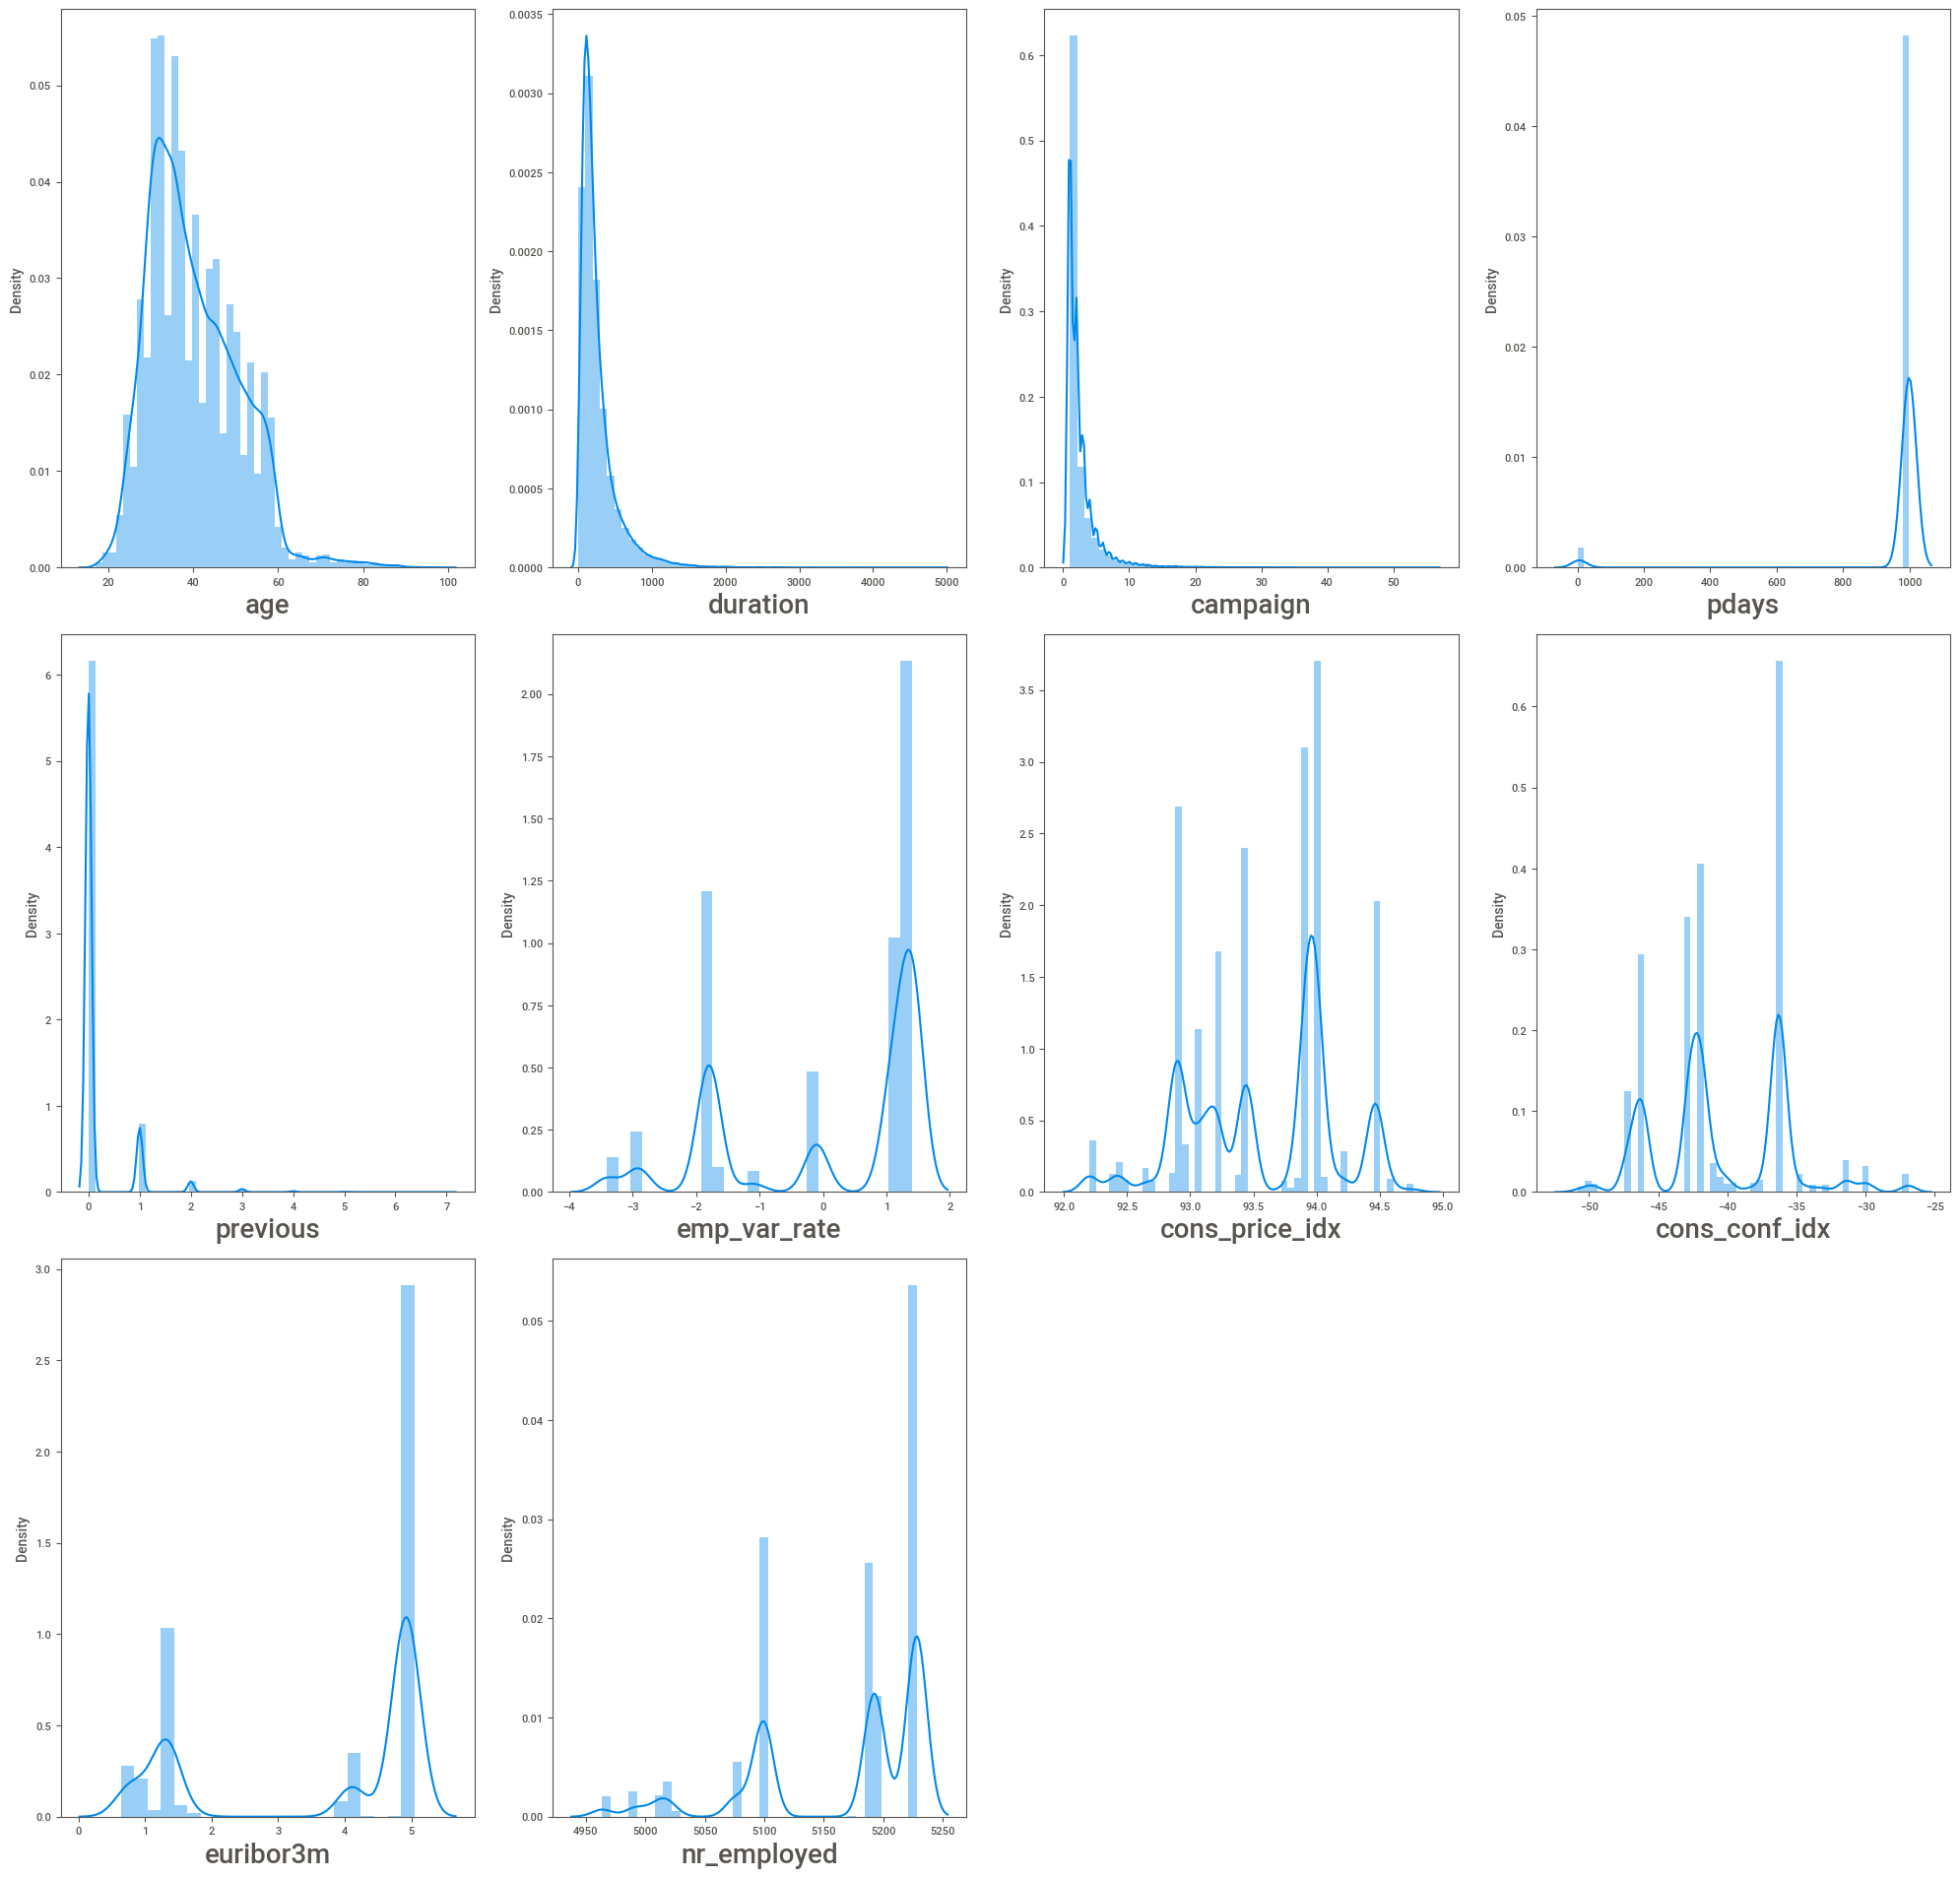

In [78]:
plt.figure(figsize=(20,25), facecolor='white')
plotnumber = 1

for column in data1:
    if plotnumber<=10 :
        ax = plt.subplot(4,4,plotnumber)
        sns.distplot(x=data1[column].dropna(axis=0))
        plt.xlabel(column,fontsize=20)
        
    plotnumber+=1
plt.tight_layout()

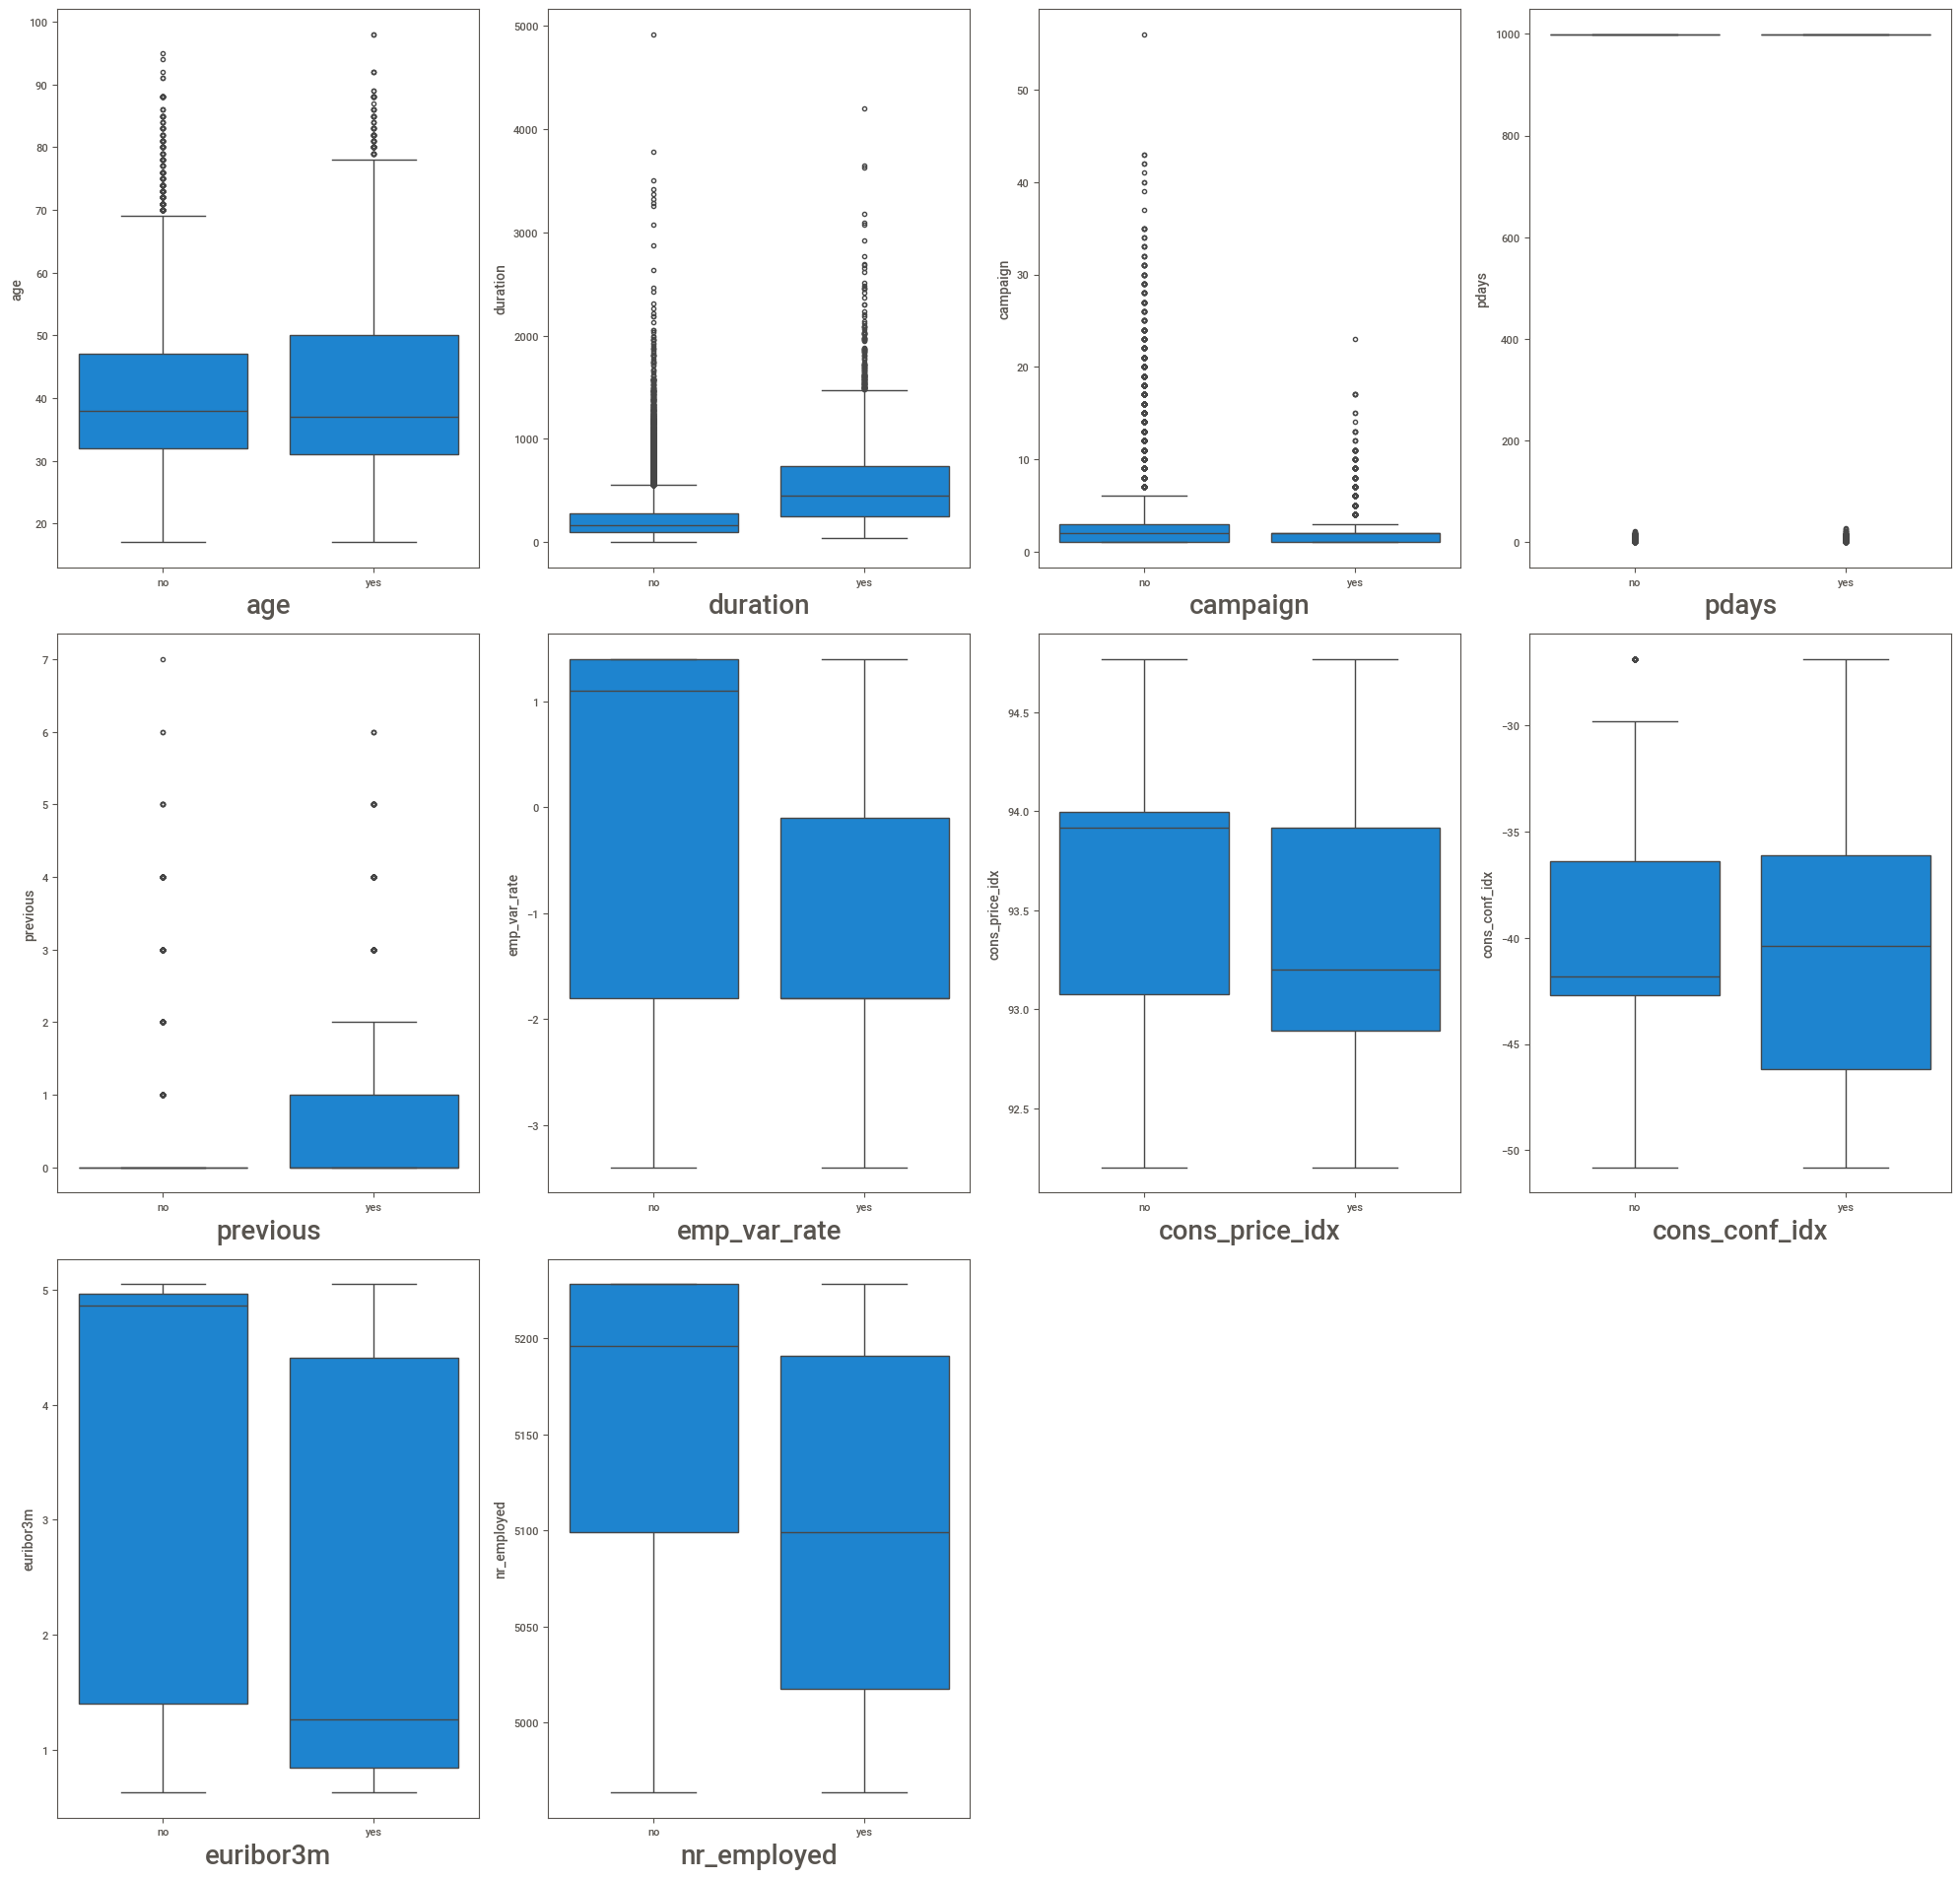

In [79]:
plt.figure(figsize=(20,25),facecolor="white")
plotnumber = 1

for column in data1:
    if plotnumber<=10 :
        ax=plt.subplot(4,4,plotnumber)
        sns.boxplot(x=data.y,y=data1[column])
        plt.xlabel(column,fontsize=20)
    
    plotnumber+=1
plt.tight_layout()

# **Data Insights from Bivariate Analysis**
### **Insights from Sumanth**

**1. Age:** From the analysis, we can see that most customers who subscribed to a term deposit are between 30 and 40 years old. Customers above 60 years are comparatively less interested in subscribing. However, the median age of both customers who subscribed and those who did not is around 38–40 years. This means age alone cannot be used to predict whether a customer will subscribe or not.

**2. Duration:** Duration refers to the total time spent talking to a customer during the last call, measured in seconds. From the plots, we can clearly see that call duration has a strong relationship with term deposit subscription. Customers who spend more time on calls are more likely to subscribe. However, we should not use this feature in our final prediction model because the call duration is only known after the conversation ends. We can use it for comparison purposes to understand how much it influences model performance.

**3. Campaign:** This feature tells us how many times a particular customer was contacted during the current marketing campaign. From the analysis, we can observe that customers who were contacted more than 20 times mostly did not subscribe to the term deposit. This suggests that repeatedly contacting the same customer may not be effective. The bank can save time and resources by avoiding too many calls to customers who are not interested.

**4. emp_var_rate:** This feature represents the employment variation rate, which is a quarterly economic indicator. From the value counts, we can see that most customers have an employment variation rate of 1.4, followed by -1.8 and 1.1. This feature may help us understand how changes in employment conditions affect customers' decisions to subscribe to a term deposit.

**5. pdays:** This feature tells us how many days have passed since a customer was last contacted during a previous campaign. The value 999 means that the customer was never contacted before. From the analysis, we can see that most customers were not previously contacted and were less interested in subscribing. On the other hand, customers who had been contacted earlier showed comparatively more interest in the term deposit. Therefore, this feature may be useful for predicting customer behaviour.

**6. Previous:** This feature represents the number of times a customer was contacted before the current campaign. From the graph, we can see that most customers had no previous contact with the bank. We can also observe that customers who had been contacted previously showed a greater tendency to subscribe. This suggests that maintaining communication with customers through different campaigns may help improve subscription rates.

**7. cons_price_idx:** This feature represents the consumer price index, which measures changes in the prices of goods and services over time. It helps us understand the economic conditions during the marketing campaign.

**8. cons_conf_idx:** This feature represents the consumer confidence index. It gives us an idea of how confident consumers are about the economy and their financial situation.

**9. euribor3m:** This feature represents the three-month Euribor interest rate, which is an important economic indicator. From the boxplot, we can clearly see a difference in the median values between customers who subscribed and those who did not. This indicates that interest rate conditions may influence customers' decisions to invest in term deposits. Therefore, this feature could be useful for our prediction model. We can confirm its importance later through machine learning models.

**10. nr_employed:** This feature represents the number of employees in the economy. It may help us understand whether employment conditions have any relationship with customers' decisions to subscribe to term deposits.

**1. Age:** The age feature has a kurtosis value below 3 and skewness below 1, which indicates a relatively flat distribution with moderate right skewness. From the analysis, we can see that most customers are between 25 and 40 years old.

**2. Duration:** The duration feature has kurtosis greater than 3 and skewness greater than 1, which indicates a highly right-skewed distribution. Most calls are relatively short, while a few calls have much longer durations. The maximum call duration is around 4,918 seconds. This feature represents the time spent talking to a customer during the last contact.

**3. Campaign:** The campaign feature also has kurtosis greater than 3 and skewness greater than 1, indicating a highly right-skewed distribution. We can observe that most customers were contacted between 1 and 5 times during the current campaign, while only a few customers received a larger number of calls.

**4. Pdays:** The pdays feature shows a highly concentrated distribution with negative skewness. Most customers have a value of 999, which means they were never contacted during any previous campaign. This tells us that a large number of customers were new to the marketing campaign.

**5. Previous:** The previous feature has kurtosis greater than 3 and skewness greater than 1, indicating a highly right-skewed distribution. From the analysis, we can see that most customers had between 0 and 3 previous contacts with the bank. This means that only a small number of customers had been contacted many times before the current campaign.

**6. emp_var_rate:** Most customers have an employment variation rate between 1 and 2. This feature helps us understand changes in employment conditions and how they may affect customer decisions regarding term deposits.

**7. cons_price_idx:** The consumer price index has moderate right skewness, and most of its values fall between 93 and 94.3. This indicates that the consumer price index did not vary significantly across most observations.

**8. cons_conf_idx:** The consumer confidence index shows moderate left skewness, with most values falling between -40 and -35. This feature helps us understand the general confidence of consumers regarding economic conditions.

**9. euribor3m:** The Euribor three-month interest rate shows a highly left-skewed distribution. The highest observed interest rate is approximately 5. This indicates that interest rates varied during the marketing campaigns and may have influenced customers' investment decisions.

**10. nr_employed:** The number of employees feature shows a left-skewed distribution, with most observations concentrated between 5,200 and 5,250. This feature gives us an idea about employment conditions during the period when the marketing campaigns were conducted.

In [80]:
data.cons_conf_idx.value_counts()

cons_conf_idx
-36.4    7763
-42.7    6685
-46.2    5794
-36.1    5175
-41.8    4374
-42.0    3616
-47.1    2458
-31.4     770
-40.8     715
-26.9     447
-30.1     357
-40.3     311
-37.5     303
-50.0     282
-29.8     267
-34.8     264
-38.3     233
-39.8     229
-40.0     212
-49.5     204
-33.6     178
-34.6     174
-33.0     172
-50.8     128
-40.4      67
-45.9      10
Name: count, dtype: int64

In [81]:
# Build a function to show categorical values disribution
def plot_bar(column):
    # temp df 
    temp_1 = pd.DataFrame()
    # count categorical values
    temp_1['No_deposit'] = data[data['y'] == 'no'][column].value_counts()
    temp_1['Yes_deposit'] = data[data['y'] == 'yes'][column].value_counts()
    temp_1.plot(kind='bar')
    plt.xlabel(f'{column}')
    plt.ylabel('Number of clients')
    plt.title('Distribution of {} and deposit'.format(column))
    plt.show()

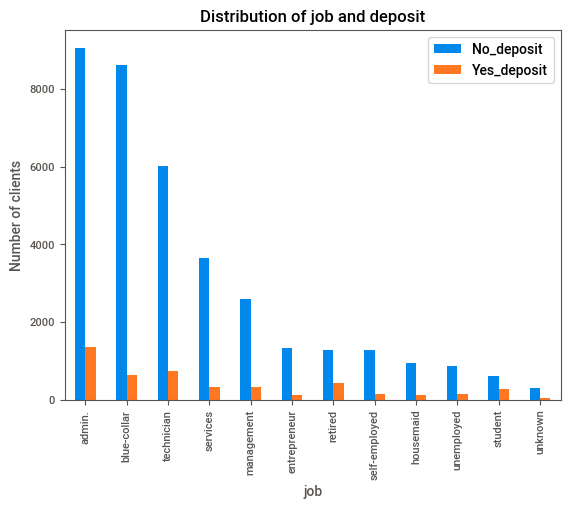

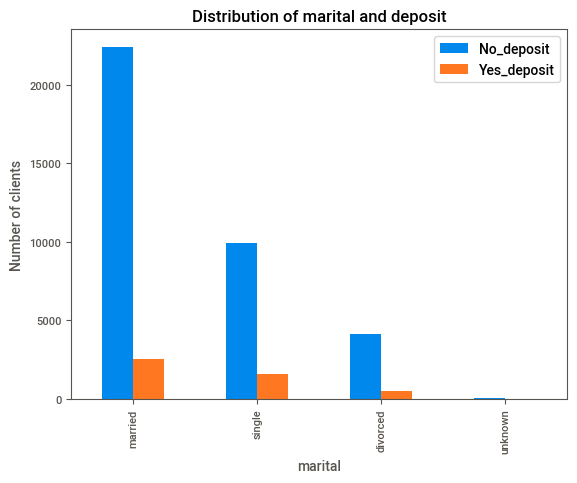

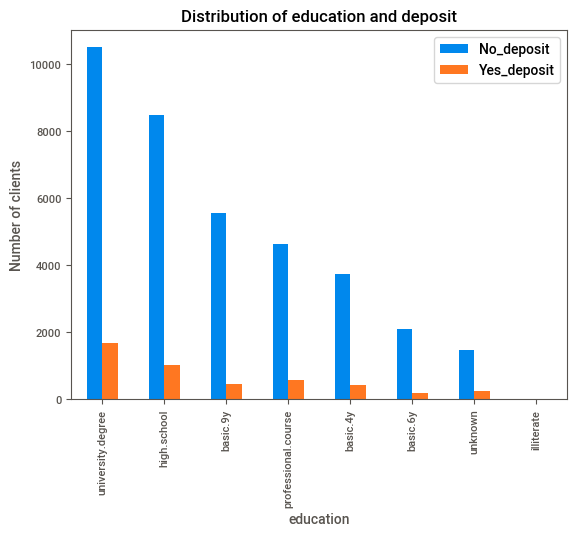

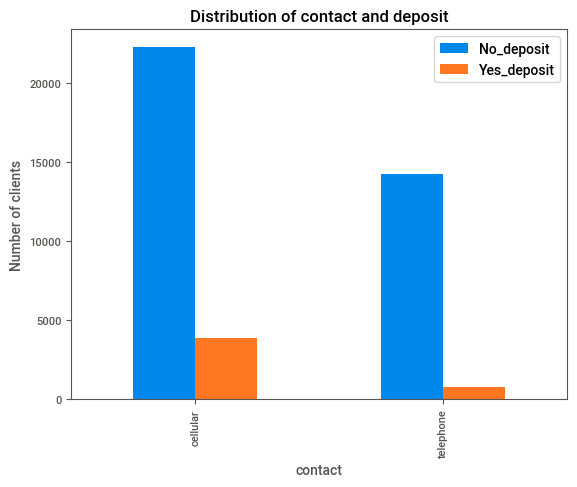

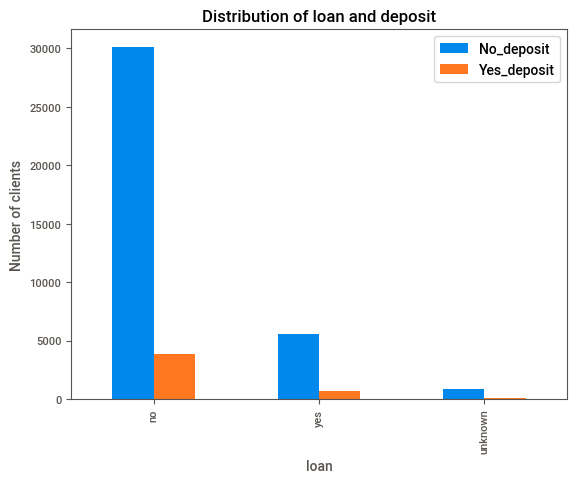

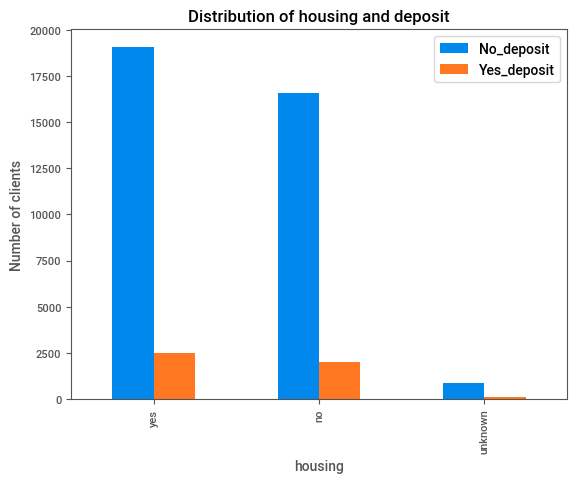

(None, None, None, None, None, None)

In [82]:
plot_bar('job'), plot_bar('marital'), plot_bar('education'), plot_bar('contact'), plot_bar('loan'), plot_bar('housing')


Primary analysis of several categorical features reveals:

Administrative staff and technical specialists opened the deposit most of all. In relative terms, a high proportion of pensioners and students might be mentioned as well. Although in absolute terms married consumers more often agreed to the service, in relative terms the single was responded better. Best communication channel is cellular. The difference is evident between consumers who already use the services of banks and received a loan. Home ownership does not greatly affect marketing company performance.

 ## Categorical Feature Distributions

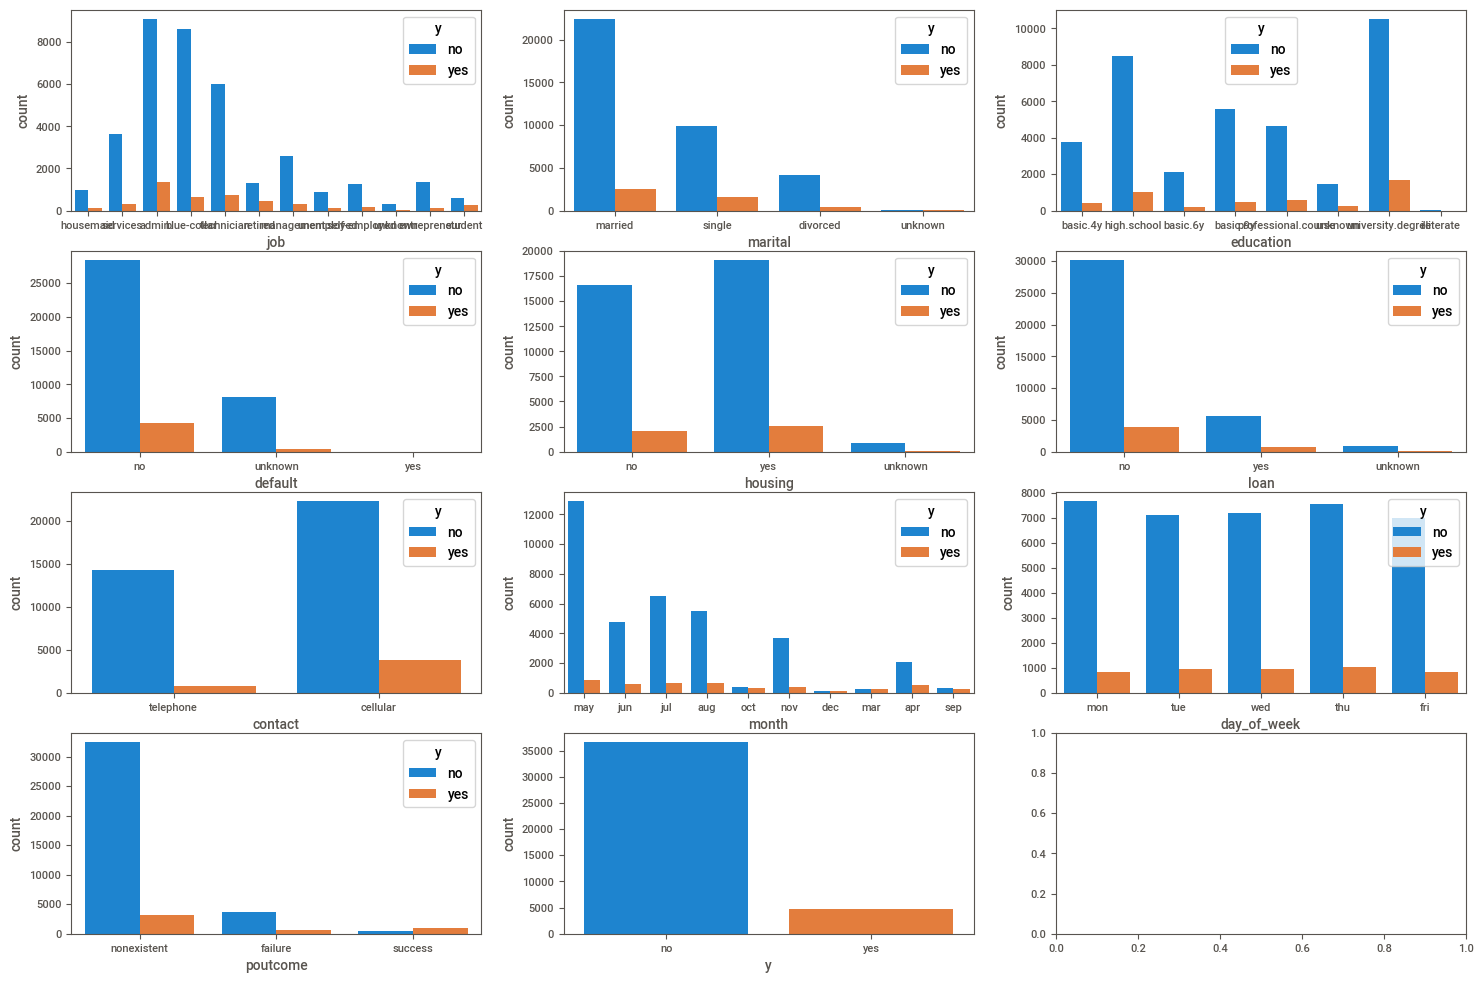

In [83]:

categorical = ['job', 'marital', 'education', 'default', 'housing', 'loan',
               'contact', 'month','day_of_week', 'poutcome','y']
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(18, 12))
for col, ax in zip(categorical[0:], axs.ravel()):
    sns.countplot(x=col, data=data, ax=ax,hue=data.y)


### **Insights from the Sumanth**

**1. Job:** This feature represents the type of job a customer has. From the count plot, we can see that customers working in the admin sector have the highest number of term deposit subscriptions. However, they also have the highest number of customers who did not subscribe. This is mainly because the admin category has more customers compared to other job categories. Customers working in blue-collar and technician roles also represent a significant portion of the dataset.

**2. Marital:** This feature represents the marital status of customers. From the analysis, we can see that most customers are married, followed by single and divorced customers. Only a small number of customers fall under the unknown category.

**3. Education:** Most customers in the dataset have a university degree. This indicates that customers with higher educational qualifications form a major part of the bank's customer base.

**4. Default:** This feature tells us whether a customer has any credit in default. From the plot, we can clearly see that almost all customers have no credit in default. Only a very small number of customers fall under the default category.

**5. Housing:** This feature indicates whether a customer has a housing loan or not. The analysis shows that a large number of customers have housing loans. However, the number of customers with and without housing loans is relatively comparable.

**6. Loan:** This feature tells us whether a customer has a personal loan. From the analysis, we can see that most customers do not have personal loans. Interestingly, customers without personal loans appear to show more interest in subscribing to a term deposit compared to customers who already have a loan.

**7. Contact:** This feature represents the communication method used to contact customers. From the plot, we can observe that most customers were contacted through cellular phones rather than telephone calls.

**8. Month:** This feature represents the month in which the customer was last contacted. From the analysis, we can see that May has the highest number of customer contacts. This indicates that the bank conducted a large number of marketing calls during this month.

**9. Day_of_week:** This feature represents the day of the week on which the customer was last contacted. From the plot, we can see that the distribution is almost similar across all five working days. Around 17–18% of customers did not subscribe, while approximately 2.1–2.5% subscribed on any given day. This suggests that the day of contact may not have a significant impact on the customer's decision to subscribe.

**10. Poutcome:** This feature represents the outcome of the previous marketing campaign. From the analysis, we can see that most customers do not have any previous campaign outcome recorded, which means they were either new customers or had no previous campaign history. Interestingly, customers whose previous campaign was successful show a higher tendency to subscribe again. Therefore, the successful category of this feature may be useful for predicting future subscriptions.

**11. Y (Target Variable):** This feature represents whether a customer subscribed to the term deposit or not. From the overall distribution, we can see that the majority of customers did not subscribe. Only a smaller percentage of customers showed interest in the term deposit. This indicates that our dataset is imbalanced, which is something we should consider while building our machine learning models.

**1. Job:** From the analysis, we can observe that customers working in admin, blue-collar and technician roles account for the highest number of term deposit subscriptions. On the other hand, unemployed people, self-employed individuals, entrepreneurs and students account for fewer subscriptions. This could be because these job categories have fewer customers in the dataset.

**2. Education:** Customers with a university degree appear to have a higher number of term deposit subscriptions. This suggests that educational background may have some relationship with customers' investment decisions.

**3. Default:** Customers who do not have credit in default are more likely to subscribe to a term deposit. Customers with credit defaults show comparatively less interest in subscribing.

**4. Loan:** From the analysis, we can see that customers without personal loans are more interested in subscribing to term deposits than those who already have personal loans. This may indicate that existing financial commitments influence a customer's investment decisions.

**5. Month:** The analysis shows that the highest conversion rates are observed between May and August. This suggests that the timing of marketing campaigns may influence customer interest in term deposit subscriptions

In [84]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null 

 ## Data Preprocessing

In [85]:
data.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp_var_rate      0
cons_price_idx    0
cons_conf_idx     0
euribor3m         0
nr_employed       0
y                 0
dtype: int64

In [86]:
data.job=data.job.map({'admin.':1,'blue-collar':2,'technician':3,'services':4,'management':5,'retired':6,
                       'entrepreneur':7,'self-employed':8,'housemaid':9,'unemployed':10,'student':11 })

In [87]:
data.marital.value_counts(())

marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

In [88]:
data.education.value_counts()

education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

In [89]:
data.education=data.education.map({'university.degree':1,'high.school':2,'basic.9y':3,'professional.course':4,
                                   'basic.4y':5,'basic.6y':6,'illiterate':7})

In [90]:
data.default.value_counts()

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

In [91]:
data.default=data.default.map({'no':0,'yes':1})

In [92]:
data.housing.value_counts()

housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

In [93]:
data.housing=data.housing.map({'no':0,'yes':1})

In [94]:
data.loan.value_counts()

loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

In [95]:
data.loan=data.loan.map({'no':0,'yes':1})

In [96]:
data.month.value_counts()

month
may    13769
jul     7174
aug     6178
jun     5318
nov     4101
apr     2632
oct      718
sep      570
mar      546
dec      182
Name: count, dtype: int64

In [97]:
data.month=data.month.map({'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
                           'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12})

In [98]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             40858 non-null  float64
 2   marital         41188 non-null  object 
 3   education       39457 non-null  float64
 4   default         32591 non-null  float64
 5   housing         40198 non-null  float64
 6   loan            40198 non-null  float64
 7   contact         41188 non-null  object 
 8   month           41188 non-null  int64  
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null 

In [99]:
data.contact.value_counts()

contact
cellular     26144
telephone    15044
Name: count, dtype: int64

In [100]:
## Converting the numerical equivalent
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
data['contact']=le.fit_transform(data['contact'])

In [101]:
data.day_of_week.value_counts()

day_of_week
thu    8623
mon    8514
wed    8134
tue    8090
fri    7827
Name: count, dtype: int64

In [102]:
data.day_of_week=data.day_of_week.map({'mon':1,'tue':2,'wed':3,'thu':4,'fri':5})

In [103]:
data.poutcome.value_counts()

poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64

In [104]:
data.poutcome=data.poutcome.map({'nonexistent':0,'failure':1,'success':2})

In [105]:
data.y.value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [106]:
data.y=data.y.map({'no':0,'yes':1})

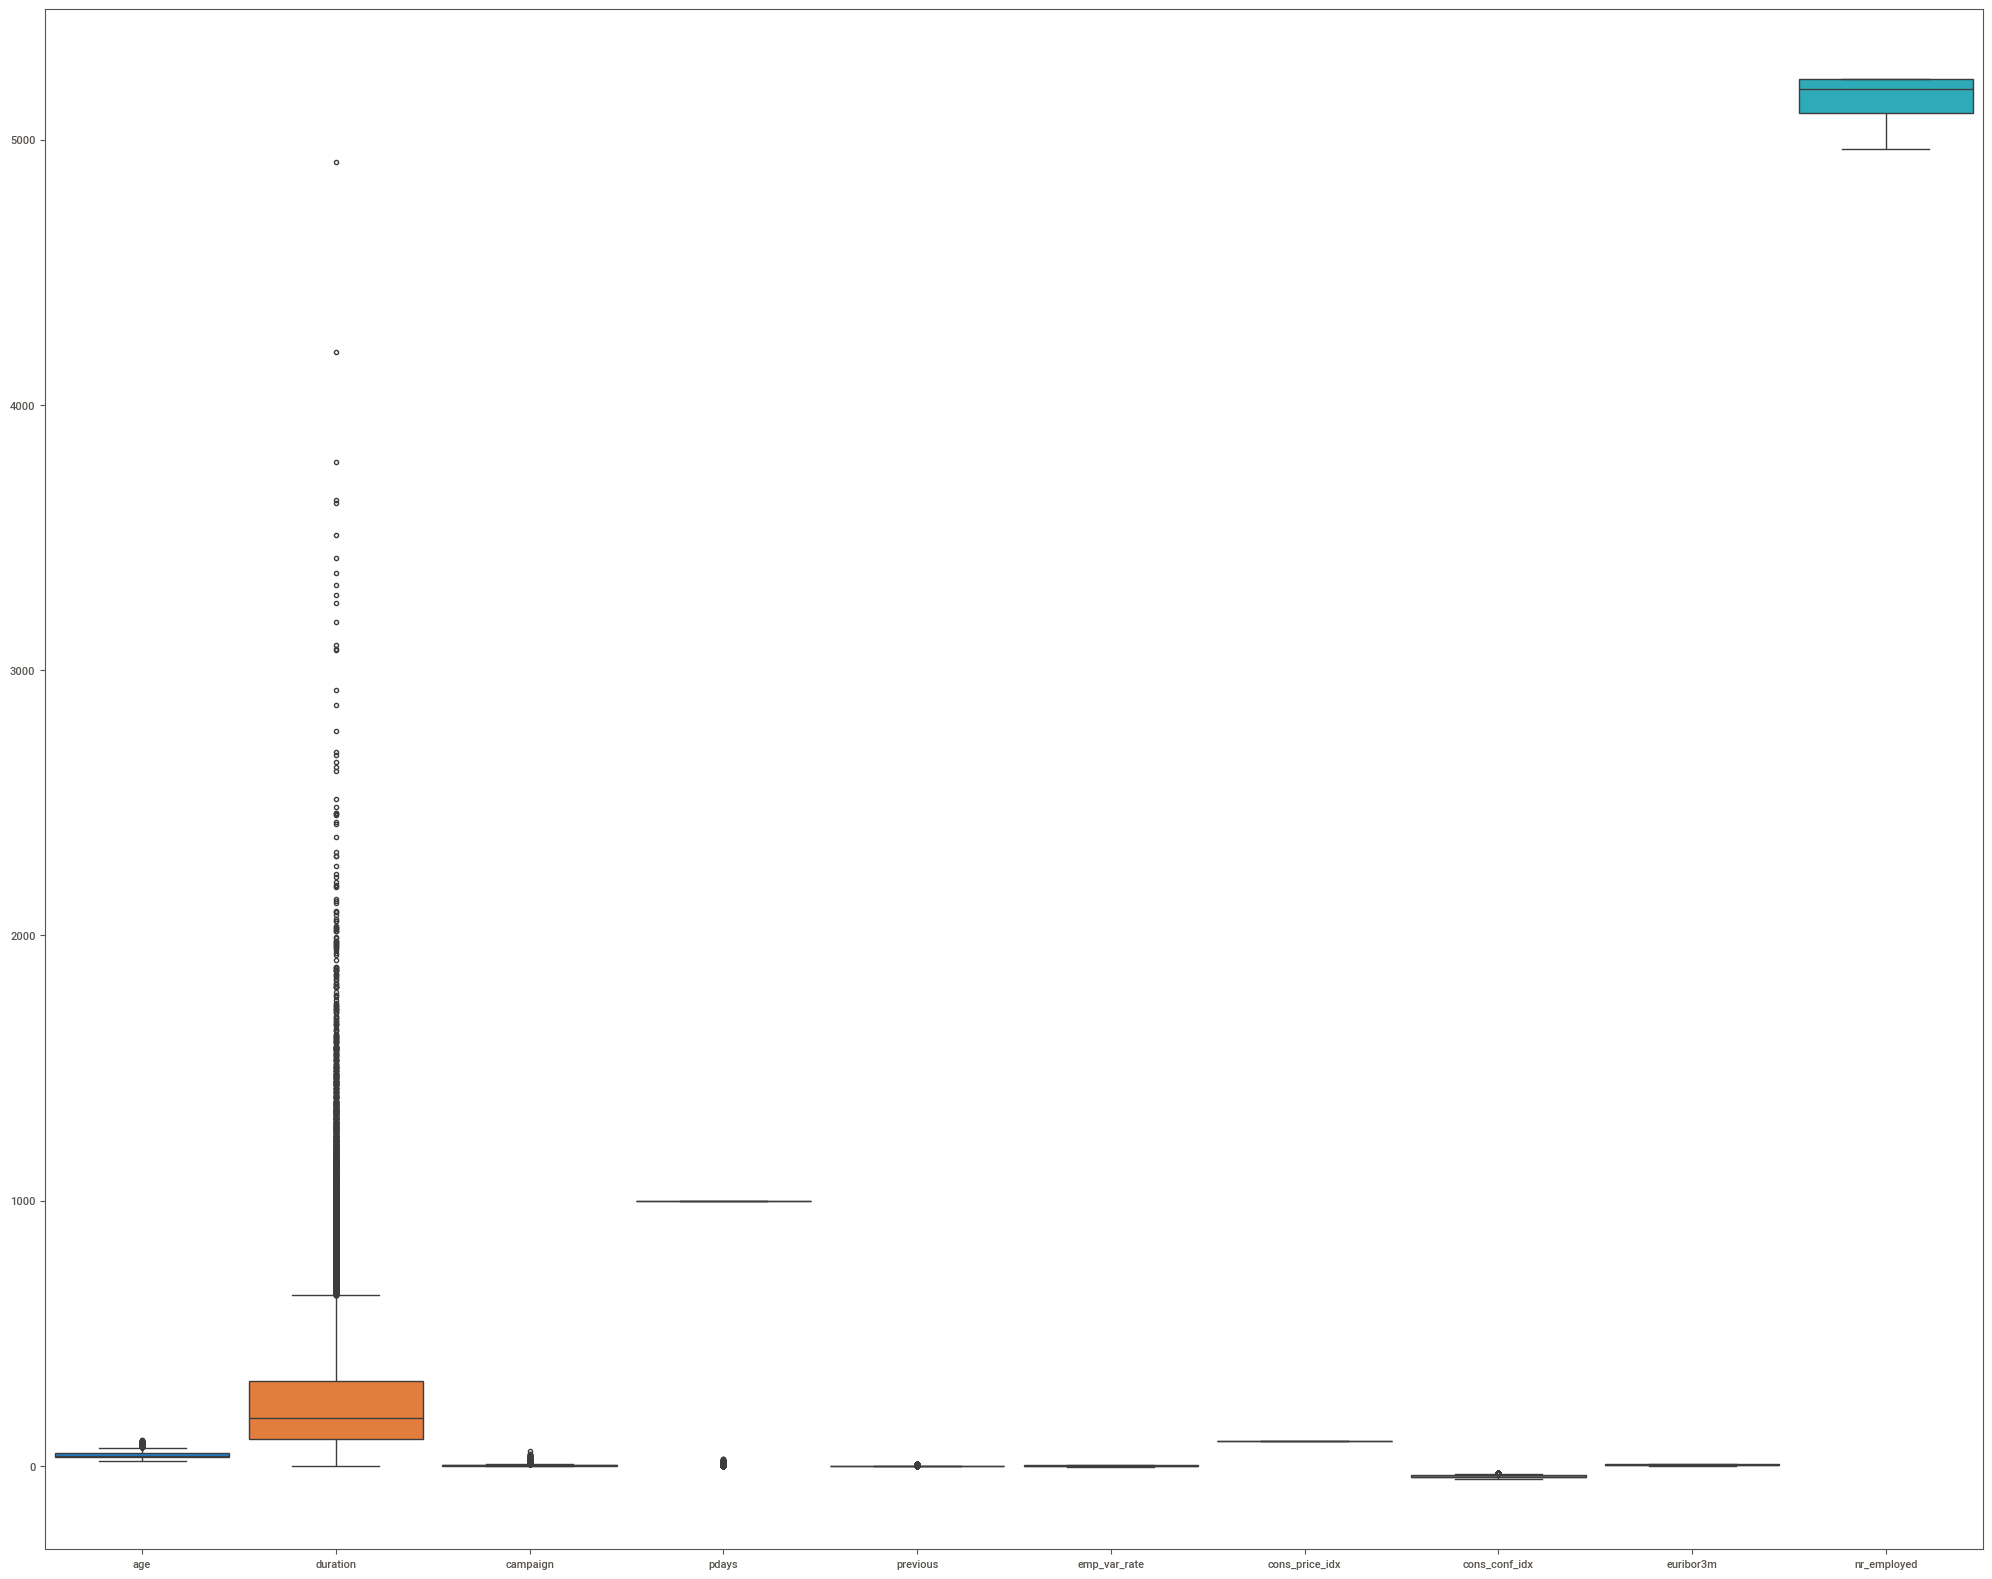

In [107]:
## Lets check outliers in any
## chekcing the outliers
fig, ax = plt.subplots(figsize=(25,20))
sns.boxplot(data=data1, width= 0.9,ax=ax,  fliersize=3)
plt.show()

<Axes: ylabel='pdays'>

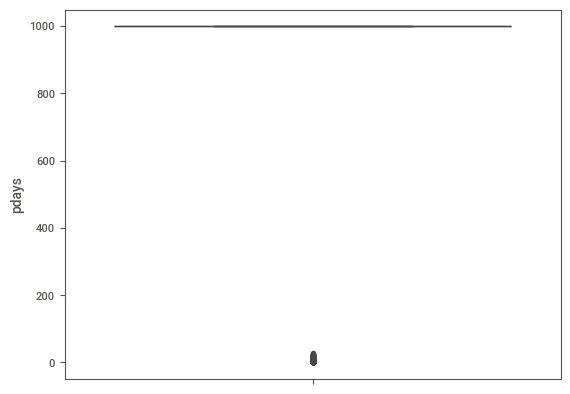

In [108]:
sns.boxplot(data.pdays)

for this dataset no outlier treatment is required

## Feature Selection

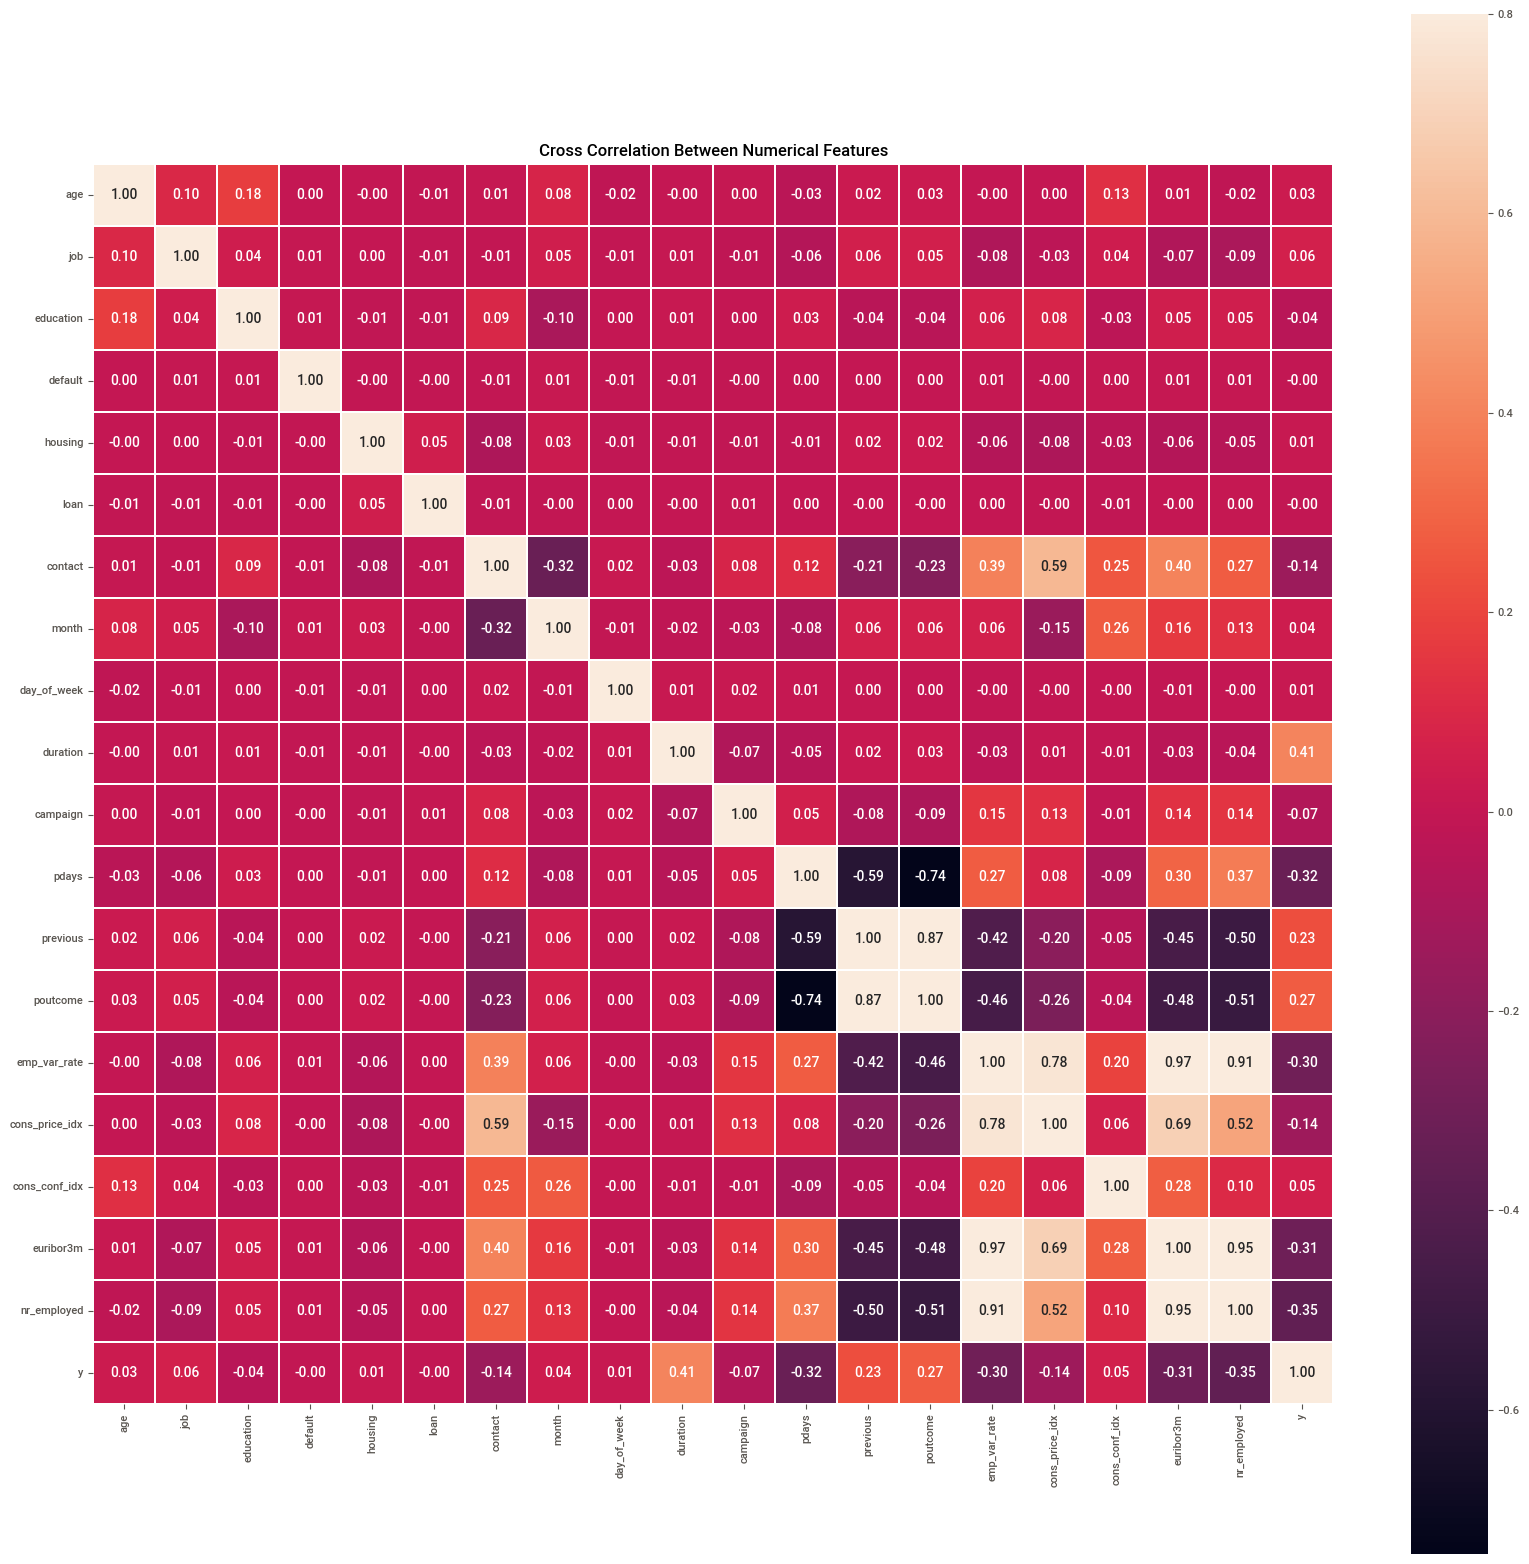

In [109]:
plt.figure(figsize=(20, 20))
ax = sns.heatmap(
    data.corr(numeric_only=True),
    vmax=0.8,
    square=True,
    fmt='.2f',
    annot=True,
    linecolor='white',
    linewidths=0.01
)
plt.title('Cross Correlation Between Numerical Features')
plt.show()

In [110]:
data2 = data.drop(['emp_var_rate','nr_employed'],axis=1)
data2.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons_price_idx,cons_conf_idx,euribor3m,y
0,56,9.0,married,5.0,0.0,0.0,0.0,1,5,1,261,1,999,0,0,93.994,-36.4,4.857,0
1,57,4.0,married,2.0,NaN,0.0,0.0,1,5,1,149,1,999,0,0,93.994,-36.4,4.857,0
2,37,4.0,married,2.0,0.0,1.0,0.0,1,5,1,226,1,999,0,0,93.994,-36.4,4.857,0
3,40,1.0,married,6.0,0.0,0.0,0.0,1,5,1,151,1,999,0,0,93.994,-36.4,4.857,0
4,56,4.0,married,2.0,0.0,0.0,1.0,1,5,1,307,1,999,0,0,93.994,-36.4,4.857,0


In [111]:
## checking the duplicate rows
data2.duplicated().sum()

np.int64(12)

In [112]:
## droping the duplicate rows
data2.drop_duplicates(inplace=True)

In [113]:
## checking the constant features
data2.describe()
## the standard deviation of all features are not 0 ,so the there are constant features in the dataset.

,age,job,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons_price_idx,cons_conf_idx,euribor3m,y
count,41176.00000,40846.000000,39446.000000,32580.000000,40186.000000,40186.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,3.447167,2.662754,0.000092,0.536779,0.155477,0.365286,6.607733,2.979600,258.315815,2.567879,962.464810,0.173013,0.169953,93.575720,-40.502863,3.621293,0.112663
std,10.42068,2.602077,1.564376,0.009596,0.498652,0.362363,0.481516,2.041013,1.411539,259.305321,2.770318,186.937102,0.494964,0.455811,0.578839,4.627860,1.734437,0.316184
min,17.00000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,92.201000,-50.800000,0.634000,0.000000
25%,32.00000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2.000000,102.000000,1.000000,999.000000,0.000000,0.000000,93.075000,-42.700000,1.344000,0.000000
50%,38.00000,3.000000,2.000000,0.000000,1.000000,0.000000,0.000000,6.000000,3.000000,180.000000,2.000000,999.000000,0.000000,0.000000,93.749000,-41.800000,4.857000,0.000000
75%,47.00000,5.000000,4.000000,0.000000,1.000000,0.000000,1.000000,8.000000,4.000000,319.000000,3.000000,999.000000,0.000000,0.000000,93.994000,-36.400000,4.961000,0.000000
max,98.00000,11.000000,7.000000,1.000000,1.000000,1.000000,1.000000,12.000000,5.000000,4918.000000,56.000000,999.000000,7.000000,2.000000,94.767000,-26.900000,5.045000,1.000000


## Model Creation

In [114]:
## Defining X and y and creating dependent and independent variables
X = data2.drop(columns = ['y']) ## independent variable
y = data2['y'] ## Dependent or target variable"

In [115]:
X

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons_price_idx,cons_conf_idx,euribor3m
0,56,9.0,married,5.0,0.0,0.0,0.0,1,5,1,261,1,999,0,0,93.994,-36.4,4.857
1,57,4.0,married,2.0,NaN,0.0,0.0,1,5,1,149,1,999,0,0,93.994,-36.4,4.857
2,37,4.0,married,2.0,0.0,1.0,0.0,1,5,1,226,1,999,0,0,93.994,-36.4,4.857
3,40,1.0,married,6.0,0.0,0.0,0.0,1,5,1,151,1,999,0,0,93.994,-36.4,4.857
4,56,4.0,married,2.0,0.0,0.0,1.0,1,5,1,307,1,999,0,0,93.994,-36.4,4.857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,6.0,married,4.0,0.0,1.0,0.0,0,11,5,334,1,999,0,0,94.767,-50.8,1.028
41184,46,2.0,married,4.0,0.0,0.0,0.0,0,11,5,383,1,999,0,0,94.767,-50.8,1.028
41185,56,6.0,married,1.0,0.0,1.0,0.0,0,11,5,189,2,999,0,0,94.767,-50.8,1.028
41186,44,3.0,married,4.0,0.0,0.0,0.0,0,11,5,442,1,999,0,0,94.767,-50.8,1.028


In [116]:
y

0        0
1        0
2        0
3        0
4        0
        ..
41183    1
41184    0
41185    0
41186    1
41187    0
Name: y, Length: 41176, dtype: int64

In [118]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Separate numerical and categorical columns
num_cols = X.select_dtypes(include=['number']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# Handle missing values
num_imputer = SimpleImputer(strategy='mean')
cat_imputer = SimpleImputer(strategy='most_frequent')

X[num_cols] = num_imputer.fit_transform(X[num_cols])
X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])

# Encode categorical variables
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Scale the data
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)

In [119]:
from imblearn.over_sampling import SMOTE
from collections import Counter
sm = SMOTE(random_state=42)
print("Before SMOTE:", Counter(y))
X_resampled, y_resampled = sm.fit_resample(X_scaled, y)
print("After SMOTE:", Counter(y_resampled))


Before SMOTE: Counter({0: 36537, 1: 4639})
After SMOTE: Counter({0: 36537, 1: 36537})


In [121]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Apply SMOTE
sm = SMOTE(random_state=42)
X_sm, y_sm = sm.fit_resample(X_scaled, y)

# Split the data
x_train, x_test, y_train, y_test = train_test_split(
    X_sm, y_sm,
    test_size=0.20,
    random_state=355,
    stratify=y_sm
)

##  Logistic Regression Model

In [122]:
##Model1 creation
from sklearn.linear_model import LogisticRegression
model1 = LogisticRegression()## object Creation

model1.fit(x_train,y_train)## fitting the model with training data

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [123]:
y_pred = model1.predict(x_test)

In [124]:
pd.crosstab(y_test,y_pred)

col_0,0,1
y,,
0,6219,1089
1,1023,6284


In [125]:
## calculating accuracy
from sklearn.metrics import accuracy_score,auc, confusion_matrix,precision_score,recall_score,f1_score,classification_report
accuracy = accuracy_score(y_test,y_pred)
accuracy

0.8554909339719466

In [126]:
# Precison
Precision = precision_score(y_test,y_pred)
Precision

0.8522989285229893

In [127]:
# Recall
Recall = recall_score(y_test,y_pred)
Recall

0.8599972628985904

In [128]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.85      0.85      7308
           1       0.85      0.86      0.86      7307

    accuracy                           0.86     14615
   macro avg       0.86      0.86      0.86     14615
weighted avg       0.86      0.86      0.86     14615



## KNN Model

In [129]:
### creating 2nd model
from sklearn.neighbors import KNeighborsClassifier
model2 = KNeighborsClassifier()
model2.fit(x_train,y_train)
y_hat1=model2.predict(x_test)

In [130]:
## for logestic regression model
from sklearn.metrics import roc_auc_score
score=roc_auc_score(y_test,y_pred)
score

0.8554912422867336

In [131]:
## for KNN model
from sklearn.metrics import roc_auc_score
score=roc_auc_score(y_test,y_hat1)
score

0.9262447706494039

In [132]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
model1 = make_pipeline(
    SimpleImputer(strategy='mean'),
    LogisticRegression(max_iter=1000)
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    model1,
    X,
    y,
    cv=cv,
    scoring='roc_auc'
)
print(scores)
print("Cross Validation Score:", scores.mean())
print("Std:", scores.std())


[0.92167122 0.92404978 0.92162186 0.92054546 0.91504176]
Cross Validation Score: 0.9205860147887817
Std: 0.0029996240784122227


In [133]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
# Create pipeline using your existing model2
model2_pipeline = make_pipeline(
    SimpleImputer(strategy='mean'),
    model2
)
# 5-fold cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    model2_pipeline,
    X,
    y,
    cv=cv,
    scoring='roc_auc'
)
print("ROC-AUC Scores:", scores)
print("Cross Validation Score:", scores.mean())
print("Std:", scores.std())

ROC-AUC Scores: [0.85562564 0.8371928  0.83529463 0.83995271 0.84363718]
Cross Validation Score: 0.8423405924365314
Std: 0.0072113939145742965


In [134]:
error_rate=[]
for i in range(1,11):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train,y_train)
    pred_i = knn.predict(x_test)
    error_rate.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Error rate')

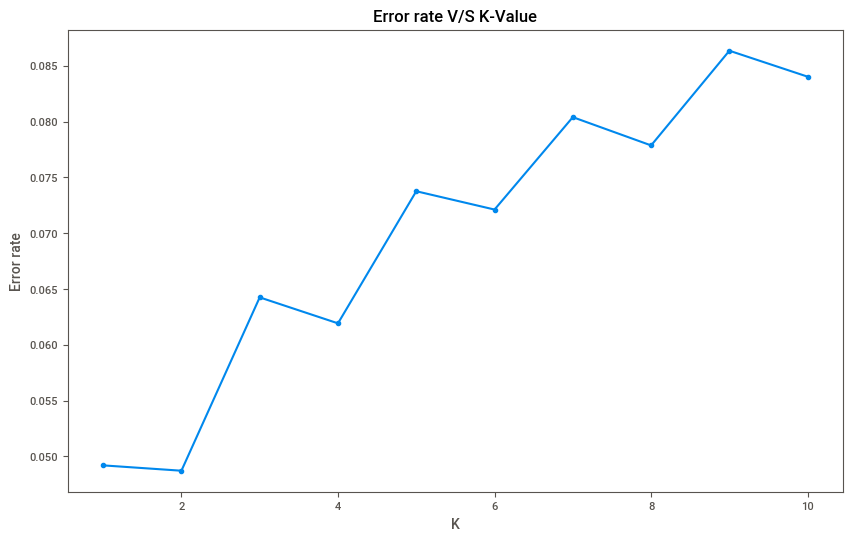

In [135]:
plt.figure(figsize=(10,6))
plt.plot(range(1,11),error_rate,marker='o')
plt.title('Error rate V/S K-Value')
plt.xlabel('K')
plt.ylabel('Error rate')

In [136]:
knn=KNeighborsClassifier(n_neighbors=2)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_test)

In [137]:
acc=accuracy_score(y_test,y_pred)
acc

0.9512829284981184

In [138]:
recall=recall_score(y_test,y_pred)
recall

0.9793348843574654

In [139]:

f1=f1_score(y_test,y_pred)
f1

0.9526091586794462

In [140]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.92      0.95      7308
           1       0.93      0.98      0.95      7307

    accuracy                           0.95     14615
   macro avg       0.95      0.95      0.95     14615
weighted avg       0.95      0.95      0.95     14615



## Bagging Classifier Model

In [141]:
# Using Bagging Classifier
from sklearn.ensemble import BaggingClassifier
# Model object creation
model_bagg1 = BaggingClassifier(
    estimator=model2,
    n_estimators=10,
    random_state=42
)
# Fitting the model
model_bagg1.fit(x_train, y_train)
# Getting predictions
y_hat_bagg = model_bagg1.predict(x_test)
# Model accuracy
print("Training Accuracy:", model_bagg1.score(x_train, y_train))
print("Testing Accuracy:", model_bagg1.score(x_test, y_test))


Training Accuracy: 0.9432080603499888
Testing Accuracy: 0.9270612384536435


In [142]:
f1_score(y_test,y_hat_bagg,average='weighted') ## f1  score calculation

0.9267361797943101

In [143]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
model_bagg_cv = make_pipeline(
    SimpleImputer(strategy='mean'),
    model_bagg1
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    model_bagg_cv,
    X,
    y,
    cv=cv,
    scoring='roc_auc'
)
print("ROC-AUC Scores:", scores)
print("Cross Validation Score:", scores.mean())
print("Std:", scores.std())


ROC-AUC Scores: [0.88150754 0.86397995 0.86358528 0.86631074 0.86700991]
Cross Validation Score: 0.8684786834391028
Std: 0.006645184672702676


## Random Forest Model

In [144]:
## model4 creation
from sklearn.ensemble import RandomForestClassifier

model4 = RandomForestClassifier(n_estimators=100)
model4.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [145]:
y_predict=model4.predict(x_test)
y_predict

array([1, 1, 0, ..., 1, 1, 0], shape=(14615,))

In [146]:
from sklearn.metrics import accuracy_score,auc, confusion_matrix,precision_score,recall_score,f1_score,classification_report
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           0       0.97      0.93      0.95      7308
           1       0.93      0.98      0.95      7307

    accuracy                           0.95     14615
   macro avg       0.95      0.95      0.95     14615
weighted avg       0.95      0.95      0.95     14615



In [147]:
f_Score=f1_score(y_test,y_predict)
f_Score

0.954816252761229

In [148]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model4,X,y,cv=5,scoring='roc_auc')
print(scores)
print("Cross validation Score:",scores.mean())
print("Std :",scores.std())
#std of < 0.05 is good

[0.27999591 0.21885851 0.19352487 0.09415577 0.14596301]
Cross validation Score: 0.18649961542273694
Std : 0.06325916794947738


## SVM Model

In [149]:
from sklearn.svm import SVC
svc=SVC()
svc.fit(x_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [150]:
y_pred=svc.predict(x_test)

In [151]:
acc=accuracy_score(y_test,y_pred)
acc

0.8970236058843654

In [152]:
from sklearn.metrics import accuracy_score,auc, confusion_matrix,precision_score,recall_score,f1_score,classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.94      0.85      0.89      7308
           1       0.86      0.95      0.90      7307

    accuracy                           0.90     14615
   macro avg       0.90      0.90      0.90     14615
weighted avg       0.90      0.90      0.90     14615



In [154]:
f_Score=f1_score(y_test,y_pred)
f_Score

0.9020373624943046

## Decision Tree Model

In [155]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
y_pred=dt.predict(x_test)


In [156]:

acc=accuracy_score(y_test,y_pred)
acc

0.9281560041053712

In [157]:

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.93      7308
           1       0.92      0.94      0.93      7307

    accuracy                           0.93     14615
   macro avg       0.93      0.93      0.93     14615
weighted avg       0.93      0.93      0.93     14615



In [158]:
f_Score=f1_score(y_test,y_pred)
f_Score

0.9286684782608695

## Naive Bayes Model

In [159]:
from sklearn.naive_bayes import BernoulliNB
nb=BernoulliNB(alpha=0.01)
nb.fit(x_train,y_train)
y_pred=nb.predict(x_test)

In [160]:
acc=accuracy_score(y_test,y_pred)
acc

0.7393089291823469

In [161]:
recall=recall_score(y_test,y_pred)
recall

0.6778431640892295

In [162]:
f1=f1_score(y_test,y_pred)
f1

0.7222222222222222

In [163]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.71      0.80      0.75      7308
           1       0.77      0.68      0.72      7307

    accuracy                           0.74     14615
   macro avg       0.74      0.74      0.74     14615
weighted avg       0.74      0.74      0.74     14615



## GradientBoostingClassifier Model

In [164]:
# importing the 5th model library

from sklearn.ensemble import GradientBoostingClassifier
gbm=GradientBoostingClassifier() ## object creation
gbm.fit(x_train,y_train) ## fitting the data
y_gbm=gbm.predict(x_test)

In [165]:
acc=accuracy_score(y_test,y_gbm)
acc

0.9317824153267191

In [166]:
recall=recall_score(y_test,y_pred)
recall

0.6778431640892295

In [167]:
# Precison
Precision = precision_score(y_test,y_pred)
Precision

0.7728194726166329

In [168]:
f1=f1_score(y_test,y_pred)
f1

0.7222222222222222

In [169]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.71      0.80      0.75      7308
           1       0.77      0.68      0.72      7307

    accuracy                           0.74     14615
   macro avg       0.74      0.74      0.74     14615
weighted avg       0.74      0.74      0.74     14615



## XGB Model

In [170]:
from xgboost import XGBClassifier

In [171]:
xgb=XGBClassifier()
xgb.fit(x_train,y_train)
y_pred=xgb.predict(x_test)

In [172]:
acc=accuracy_score(y_test,y_pred)
acc

0.9530619226821758

In [173]:
recall=recall_score(y_test,y_pred)
recall

0.9585329136444505

In [174]:
f1=f1_score(y_test,y_pred)
f1

0.9533142779365728

In [176]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.96      0.95      0.95      7308
           1       0.95      0.96      0.95      7307

    accuracy                           0.95     14615
   macro avg       0.95      0.95      0.95     14615
weighted avg       0.95      0.95      0.95     14615



## Hyperparameter Tuning for the Best Model

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

n_estimators = [int(x) for x in np.linspace(start=200, stop=1000, num=10)]
max_features = ['auto', 'sqrt']
max_depth = [int(x) for x in np.linspace(10, 40, num=9)]
max_depth.append(None)
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 4]
bootstrap = [True, False]

random_grid = {'n_estimators': n_estimators, 'max_features': max_features,
               'max_depth': max_depth, 'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf, 'bootstrap': bootstrap}

rf_clf1 = RandomForestClassifier(random_state=42)

rf_cv = RandomizedSearchCV(estimator=model4, scoring='f1',param_distributions=random_grid, n_iter=100, cv=3, 
                               verbose=2, random_state=42, n_jobs=-1)

rf_cv.fit(x_train, y_train)
rf_best_params = rf_cv.best_params_
print(f"Best paramters: {rf_best_params})")

Fitting 3 folds for each of 100 candidates, totalling 300 fits


Inference: It's evident that Random Forest is performing better than other models